In [1]:
# Cell 1: Import libraries and load data
import sys
import numpy as np
import pandas as pd
import sklearn
import time 
import matplotlib.pyplot as plt

from sklearn.metrics import (roc_curve, precision_recall_curve)
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import PredefinedSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Load the cleaned dataset
df = pd.read_csv(r"C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\Cleaned data\EVChargingStationUsage_cleaned.csv", low_memory=False)

# Convert timestamp columns to datetime format
df["Start Date"] = pd.to_datetime(df["Start Date"], errors="coerce")
df["End Date"] = pd.to_datetime(df["End Date"], errors="coerce")

# Convert idle time from hours to minutes for easier threshold analysis
df["idle_minutes"] = df["Idle Time Hours"] * 60

# Extract hour of day and day of week from start and end timestamps
df["start_hour"] = df["Start Date"].dt.hour
df["end_hour"] = df["End Date"].dt.hour
df["day_of_week"] = df["Start Date"].dt.day_name()

# Inspect summary statistics of idle time
print(df[["Idle Time Hours", "idle_minutes"]].describe())


       Idle Time Hours   idle_minutes
count    258950.000000  258950.000000
mean          0.482186      28.931165
std           1.374932      82.495931
min           0.000000       0.000000
25%           0.003889       0.233333
50%           0.007222       0.433333
75%           0.354167      21.250000
max          22.400556    1344.033333


,Threshold (min),Overstay sessions,Overstay rate (%),Excess idle hours
0,15,75243,29.06,102087.56
1,30,52779,20.38,86278.42
2,45,39727,15.34,74856.30
3,60,31184,12.04,66056.73
4,90,20904,8.07,53304.60
5,120,15171,5.86,44425.95


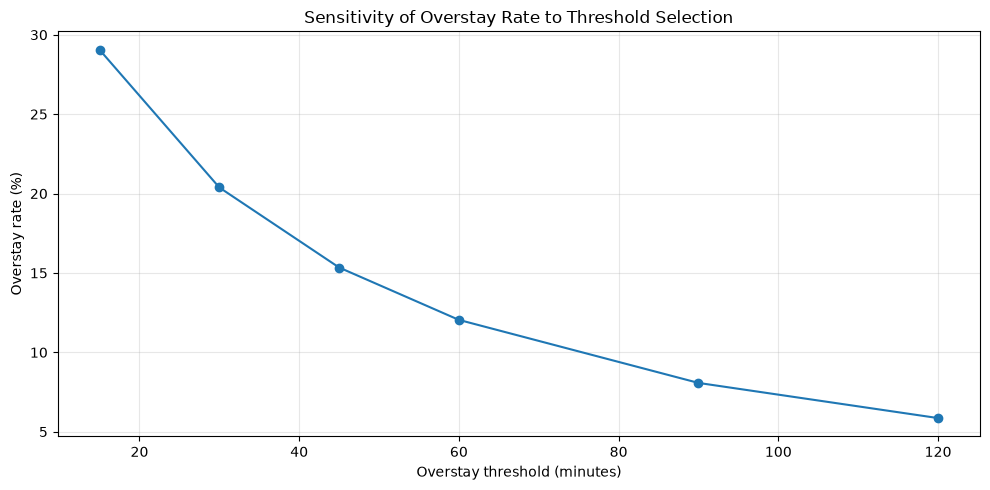

In [2]:
# Cell 2: Sensitivity analysis of overstay thresholds
thresholds = [15, 30, 45, 60, 90, 120]

threshold_results = []

for threshold in thresholds:

    overstay = df["idle_minutes"] > threshold

    threshold_results.append({
        "Threshold (min)": threshold,
        "Overstay sessions": overstay.sum(),
        "Overstay rate (%)": overstay.mean() * 100,
        "Excess idle hours": (
            df["idle_minutes"] - threshold
        ).clip(lower=0).sum() / 60
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(2))
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold (min)"],
    threshold_df["Overstay rate (%)"],
    marker="o"
)

plt.xlabel("Overstay threshold (minutes)")
plt.ylabel("Overstay rate (%)")
plt.title("Sensitivity of Overstay Rate to Threshold Selection")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

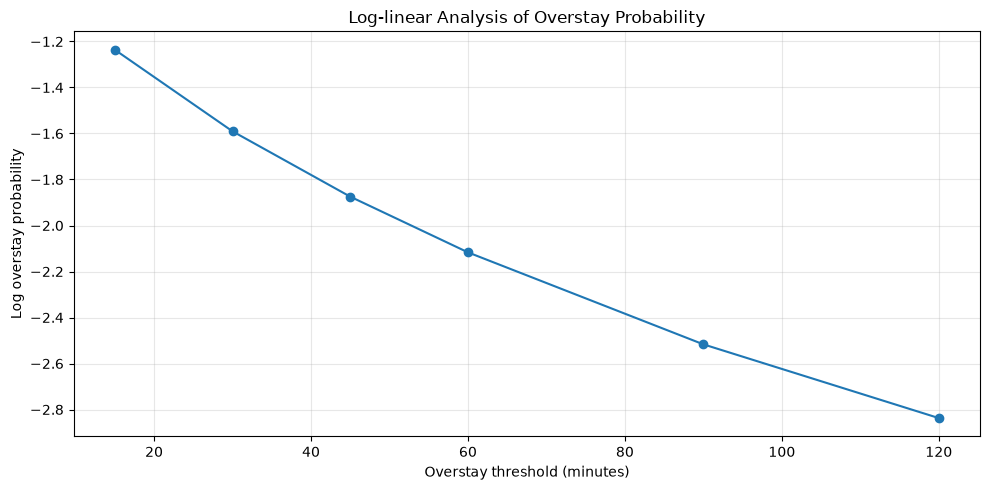

In [3]:
# Cell 3: Log-linear analysis of overstay probability
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold (min)"],
    np.log(threshold_df["Overstay rate (%)"] / 100),
    marker="o"
)

plt.xlabel("Overstay threshold (minutes)")
plt.ylabel("Log overstay probability")
plt.title("Log-linear Analysis of Overstay Probability")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Identify excessive overstay sessions
# Define the selected overstay threshold
OVERSTAY_THRESHOLD_MINS = 30

df["is_excessive_overstay"] = df["idle_minutes"] > OVERSTAY_THRESHOLD_MINS

df["excess_idle_minutes"] = np.where(
    df["is_excessive_overstay"],
    df["idle_minutes"] - OVERSTAY_THRESHOLD_MINS,
    0.0,
)

# Filter out rows with missing User ID for user-level ranking
user_df = df.dropna(subset=["User ID"]).copy()

# Aggregate overstay metrics per user
user_overstay = (
    user_df.groupby("User ID", as_index=False)
    .agg(
        total_sessions=("idle_minutes", "count"),
        overstay_sessions=("is_excessive_overstay", "sum"),
        overstay_rate_pct=("is_excessive_overstay", lambda s: s.mean() * 100),
        mean_idle_mins=("idle_minutes", "mean"),
        total_excess_hours=("excess_idle_minutes", lambda s: s.sum() / 60),
    )
    .sort_values(
        by=["overstay_sessions", "total_excess_hours"],
        ascending=[False, False],
    )
)

# Display top 10 users with excessive overstay
top_users = user_overstay.head(10)
print(top_users.to_string(index=False))

User ID  total_sessions  overstay_sessions  overstay_rate_pct  mean_idle_mins  total_excess_hours
 643155             740                514          69.459459       74.224212          628.278611
 458893             673                495          73.551263      262.305498         2676.058056
1726531             530                441          83.207547       47.596730          181.436944
 275047             567                396          69.841270      131.627954         1018.165278
 278457             773                360          46.571798       74.635317          716.121667
   2670             879                350          39.817975       92.107755         1103.803333
 128279             989                341          34.479272       29.923256          277.112222
 215785             367                283          77.111717      105.513306          487.474167
 143839             574                271          47.212544       76.607985          575.863611
 332155             

In [5]:
# Cell 5: Station-level overstay analysis
# Aggregate overstay metrics per station
station_overstay = (
    df.groupby("Station Name", as_index=False)
    .agg(
        total_sessions=("idle_minutes", "count"),
        overstay_sessions=("is_excessive_overstay", "sum"),
        overstay_rate_pct=("is_excessive_overstay", lambda s: s.mean() * 100),
        mean_idle_mins=("idle_minutes", "mean"),
        total_excess_hours=("excess_idle_minutes", lambda s: s.sum() / 60),
    )
    .sort_values(
        by=["overstay_sessions", "total_excess_hours"],
        ascending=[False, False],
    )
)

# Display top 10 stations with excessive overstay
top_stations = station_overstay.head(10)
print(top_stations.to_string(index=False))

                  Station Name  total_sessions  overstay_sessions  overstay_rate_pct  mean_idle_mins  total_excess_hours
    PALO ALTO CA / HAMILTON #2           23681               4963          20.957730       28.808305         7716.915278
     PALO ALTO CA / WEBSTER #1           14406               3376          23.434680       36.723351         6364.121111
    PALO ALTO CA / HAMILTON #1           14845               3345          22.532839       28.804624         4747.282778
     PALO ALTO CA / WEBSTER #2           12652               3265          25.806197       38.209545         5780.110833
      PALO ALTO CA / BRYANT #2           14303               2965          20.729917       32.201927         5515.576111
        PALO ALTO CA / HIGH #4           13851               2921          21.088730       24.773040         3623.271944
      PALO ALTO CA / BRYANT #1           13396               2846          21.245148       31.898547         5022.880278
     PALO ALTO CA / WEBSTER #3  

 end_hour  total_sessions  overstay_sessions  overstay_rate_pct  mean_idle_mins
      0.0            1789                610          34.097261       41.681386
      1.0             707                289          40.876945       64.963083
      2.0             315                162          51.428571       82.726402
      3.0             186                113          60.752688       98.613082
      4.0             218                159          72.935780      148.468349
      5.0             883                446          50.509626      146.271914
      6.0            2030                910          44.827586      140.455296
      7.0            4702               1921          40.854955      146.625822
      8.0            6948               1933          27.820956       94.556729
      9.0           10216               1967          19.254111       44.581878
     10.0           14553               2926          20.105820       30.525240
     11.0           19971               

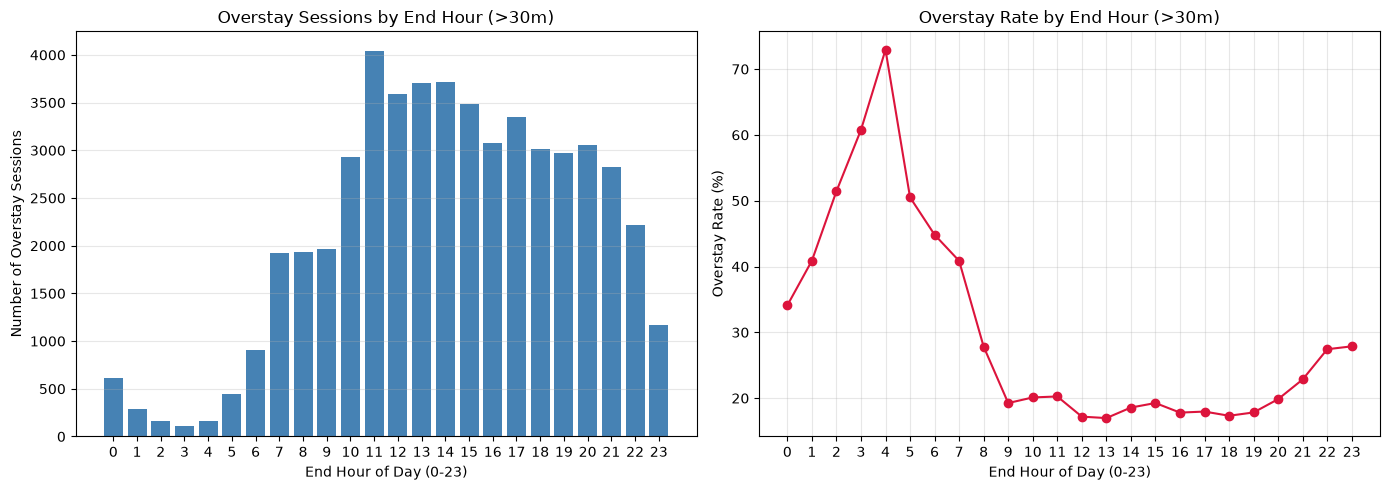

In [6]:
# Cell 6: Hourly overstay analysis
# Aggregate overstay metrics by session end hour
hourly_overstay = (
    df.dropna(subset=["end_hour"])
    .groupby("end_hour", as_index=False)
    .agg(
        total_sessions=("idle_minutes", "count"),
        overstay_sessions=("is_excessive_overstay", "sum"),
        overstay_rate_pct=("is_excessive_overstay", lambda s: s.mean() * 100),
        mean_idle_mins=("idle_minutes", "mean"),
    )
    .sort_values("end_hour")
)

print(hourly_overstay.to_string(index=False))

# Plot overstay count and overstay rate across hours of the day
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].bar(
    hourly_overstay["end_hour"],
    hourly_overstay["overstay_sessions"],
    color="steelblue",
)
ax[0].set_title(
    f"Overstay Sessions by End Hour (>{OVERSTAY_THRESHOLD_MINS}m)"
)
ax[0].set_xlabel("End Hour of Day (0-23)")
ax[0].set_ylabel("Number of Overstay Sessions")
ax[0].set_xticks(range(0, 24))
ax[0].grid(axis="y", alpha=0.3)

ax[1].plot(
    hourly_overstay["end_hour"],
    hourly_overstay["overstay_rate_pct"],
    marker="o",
    color="crimson",
)
ax[1].set_title(
    f"Overstay Rate by End Hour (>{OVERSTAY_THRESHOLD_MINS}m)"
)
ax[1].set_xlabel("End Hour of Day (0-23)")
ax[1].set_ylabel("Overstay Rate (%)")
ax[1].set_xticks(range(0, 24))
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

day_of_week  total_sessions  overstay_sessions  overstay_rate_pct  mean_idle_mins
     Monday           36747               7800          21.226223       29.631035
    Tuesday           39522               8415          21.291939       28.972253
  Wednesday           40425               8787          21.736549       28.967546
   Thursday           40109               8603          21.449051       28.590941
     Friday           40365               8518          21.102440       29.006069
   Saturday           32181               5634          17.507225       29.577567
     Sunday           29601               5022          16.965643       27.613913


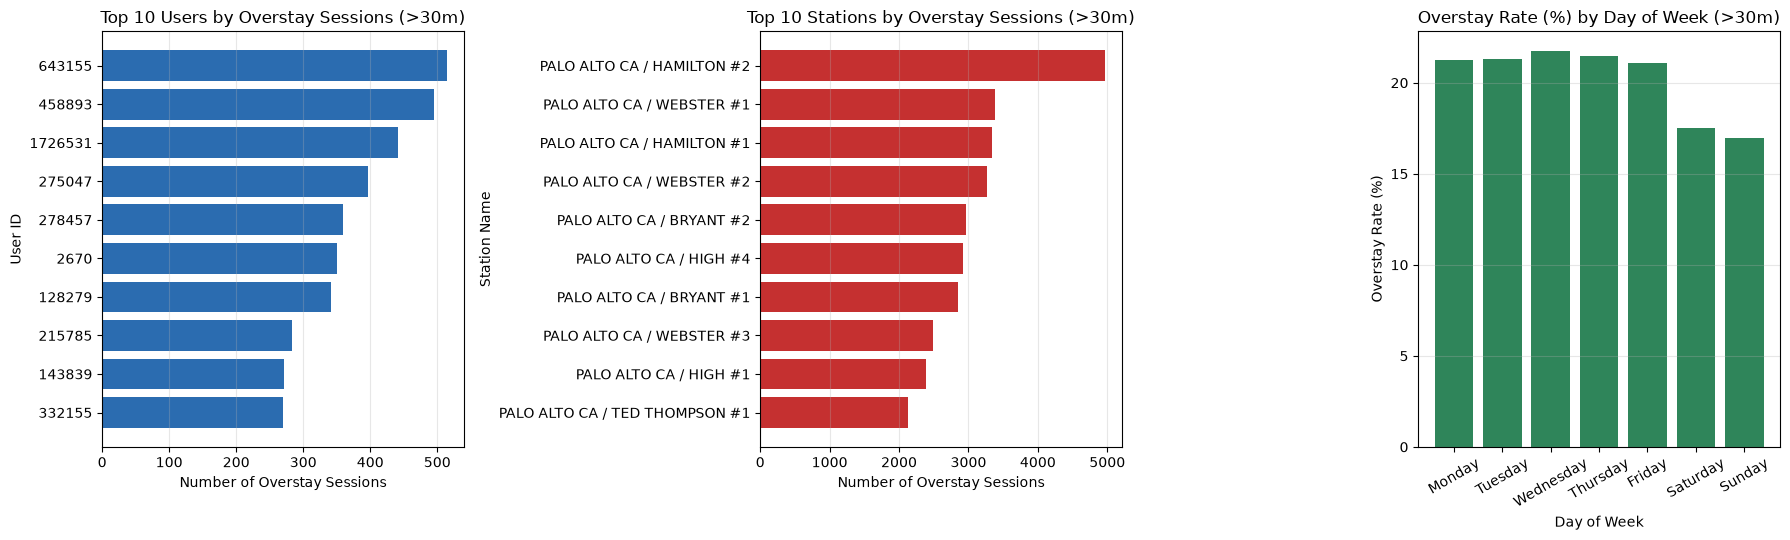

In [7]:
# Cell 7: Weekly overstay analysis and summary visualization
# Aggregate overstay metrics by day of week in calendar order
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

day_overstay = (
    df.dropna(subset=["day_of_week"])
    .groupby("day_of_week", as_index=False)
    .agg(
        total_sessions=("idle_minutes", "count"),
        overstay_sessions=("is_excessive_overstay", "sum"),
        overstay_rate_pct=("is_excessive_overstay", lambda s: s.mean() * 100),
        mean_idle_mins=("idle_minutes", "mean"),
    )
)

day_overstay["day_of_week"] = pd.Categorical(
    day_overstay["day_of_week"],
    categories=day_order,
    ordered=True
)

day_overstay = day_overstay.sort_values("day_of_week")

print(day_overstay.to_string(index=False))

# Plot 3-panel summary dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

axes[0].barh(
    top_users["User ID"].astype(str)[::-1],
    top_users["overstay_sessions"][::-1],
    color="#2b6cb0",
)
axes[0].set_title(
    f"Top 10 Users by Overstay Sessions (>{OVERSTAY_THRESHOLD_MINS}m)"
)
axes[0].set_xlabel("Number of Overstay Sessions")
axes[0].set_ylabel("User ID")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(
    top_stations["Station Name"][::-1],
    top_stations["overstay_sessions"][::-1],
    color="#c53030",
)
axes[1].set_title(
    f"Top 10 Stations by Overstay Sessions (>{OVERSTAY_THRESHOLD_MINS}m)"
)
axes[1].set_xlabel("Number of Overstay Sessions")
axes[1].set_ylabel("Station Name")
axes[1].grid(axis="x", alpha=0.3)

axes[2].bar(
    day_overstay["day_of_week"].astype(str),
    day_overstay["overstay_rate_pct"],
    color="#2f855a",
)
axes[2].set_title(
    f"Overstay Rate (%) by Day of Week (>{OVERSTAY_THRESHOLD_MINS}m)"
)
axes[2].set_xlabel("Day of Week")
axes[2].set_ylabel("Overstay Rate (%)")
axes[2].tick_params(axis="x", rotation=30)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Cell 8: Feature engineering for overstay classification
# Extract additional temporal features
df["day_of_week_num"] = df["Start Date"].dt.dayofweek
df["month"] = df["Start Date"].dt.month

df["is_weekend"] = (
    df["day_of_week_num"] >= 5
).astype(int)

# Convert the target variable to binary integers
df["is_excessive_overstay"] = df["is_excessive_overstay"].astype(int)

# Select features
features = [
    "start_hour",
    "day_of_week_num",
    "month",
    "is_weekend",
    "Station Name",
    "Plug Type"
]

target = "is_excessive_overstay"

# Prepare modelling dataset
model_df = df[
    features + [target, "Start Date", "End Date", "idle_minutes"]
].dropna().copy()

# Ensure chronological ordering
model_df = model_df.sort_values(
    "Start Date"
).reset_index(drop=True)

X = model_df[features]
y = model_df[target]

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Dataset shape: (253396, 6)

Target distribution:
is_excessive_overstay
0    0.796129
1    0.203871
Name: proportion, dtype: float64


C:\Users\harja\AppData\Local\Temp\ipykernel_21660\719299835.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week_num"] = df["Start Date"].dt.dayofweek


In [9]:
# Cell 9: Chronological 70/30 train-test split
split_idx = int(len(model_df) * 0.7)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

# Display training and test periods
print("\nTraining period:")
print(model_df["Start Date"].iloc[0],
      "to", model_df["Start Date"].iloc[split_idx - 1])

print("\nTest period:")
print(model_df["Start Date"].iloc[split_idx],
      "to", model_df["Start Date"].iloc[-1])

# Check target distributions
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

# Check for overlapping sessions
test_start = model_df["Start Date"].iloc[split_idx]

overlapping_sessions = (
    model_df["End Date"].iloc[:split_idx] >= test_start
).sum()

print("\nOverlapping training sessions:", overlapping_sessions)

Training set: (177377, 6)
Test set: (76019, 6)

Training period:
2011-07-29 20:17:00 to 2018-10-21 17:04:00

Test period:
2018-10-21 17:33:00 to 2020-12-31 18:19:00

Training target distribution:
is_excessive_overstay
0    0.770449
1    0.229551
Name: proportion, dtype: float64

Test target distribution:
is_excessive_overstay
0    0.856049
1    0.143951
Name: proportion, dtype: float64

Overlapping training sessions: 9


In [10]:
# Cell 10: Preprocessing pipeline for categorical and numerical features
categorical_features = [
    "start_hour",
    "day_of_week_num",
    "month",
    "Station Name",
    "Plug Type"
]

numerical_features = [
    "is_weekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [11]:
# Cell 11: Define classification models
models = {
    "Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

In [12]:
# Cell 12: Model training and evaluation
results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print(f"Training {name}...")
    start_time = time.time()

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    # Train model
    pipeline.fit(X_train, y_train)
    training_time = time.time() - start_time

    # Test predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Store model and predictions
    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Evaluate model performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob),
        "Training time (s)": training_time
    })

# Model comparison
results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

Training Baseline...
Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Training time (s)
Model,,,,,,,,
Baseline,0.8560,0.5000,0.0000,0.0000,0.0000,0.5000,0.1440,0.1285
Logistic Regression,0.6696,0.5356,0.1746,0.3475,0.2324,0.5546,0.1759,0.3770
Decision Tree,0.8042,0.5139,0.1855,0.1063,0.1351,0.5507,0.1677,0.3919
Random Forest,0.6325,0.5451,0.1762,0.4223,0.2486,0.5751,0.1834,2.5131


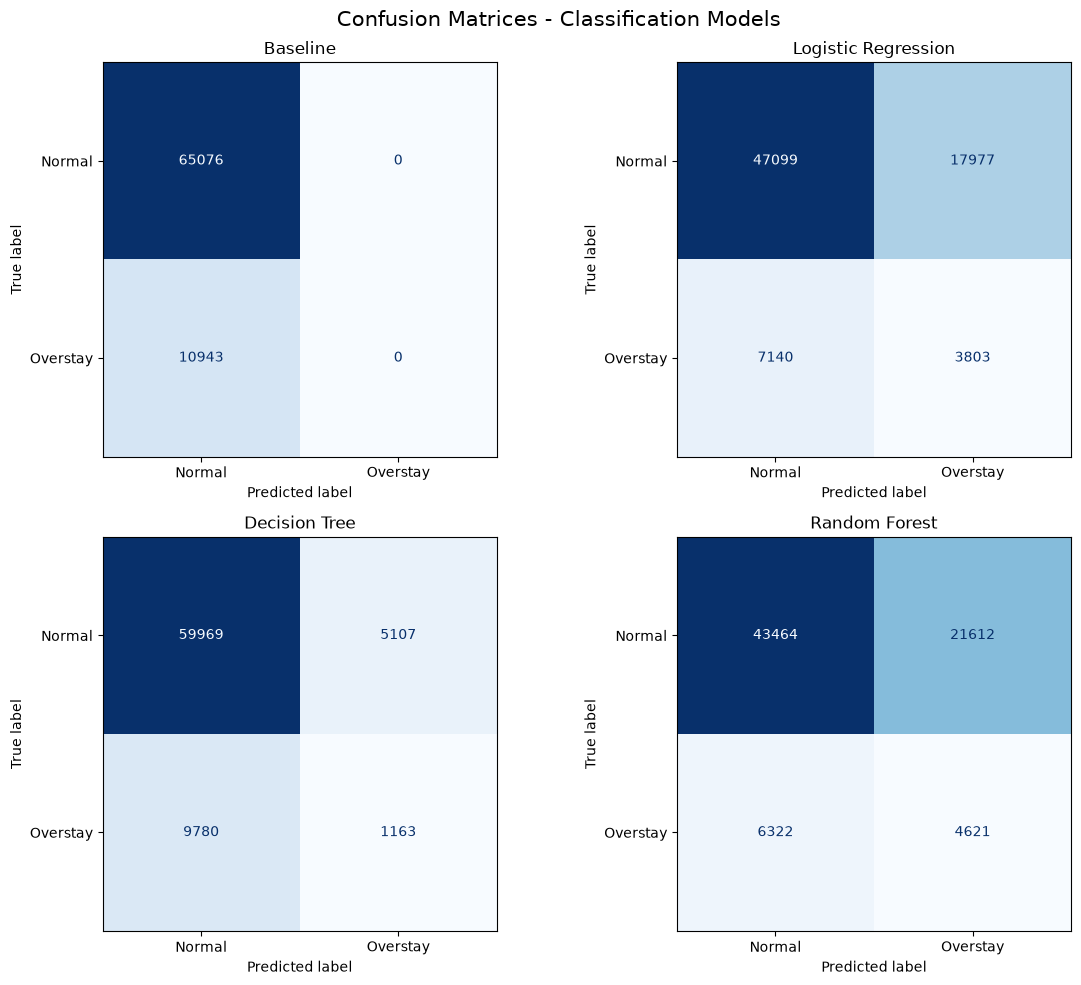

In [13]:
# Cell 14: Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Normal", "Overstay"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices - Classification Models", fontsize=15)
plt.tight_layout()
plt.show()

Total historical users: 14305
Users with at least 10 sessions: 2465

Historical user behaviour:


,total_sessions,overstay_sessions,overstay_rate,mean_idle_minutes
count,2465.000,2465.000,2465.000,2465.000
mean,58.632,14.288,0.199,26.647
std,94.483,34.931,0.198,43.417
min,10.000,0.000,0.000,0.149
25%,15.000,1.000,0.049,4.654
50%,25.000,4.000,0.143,13.096
75%,58.000,11.000,0.300,30.230
max,989.000,493.000,1.000,659.890


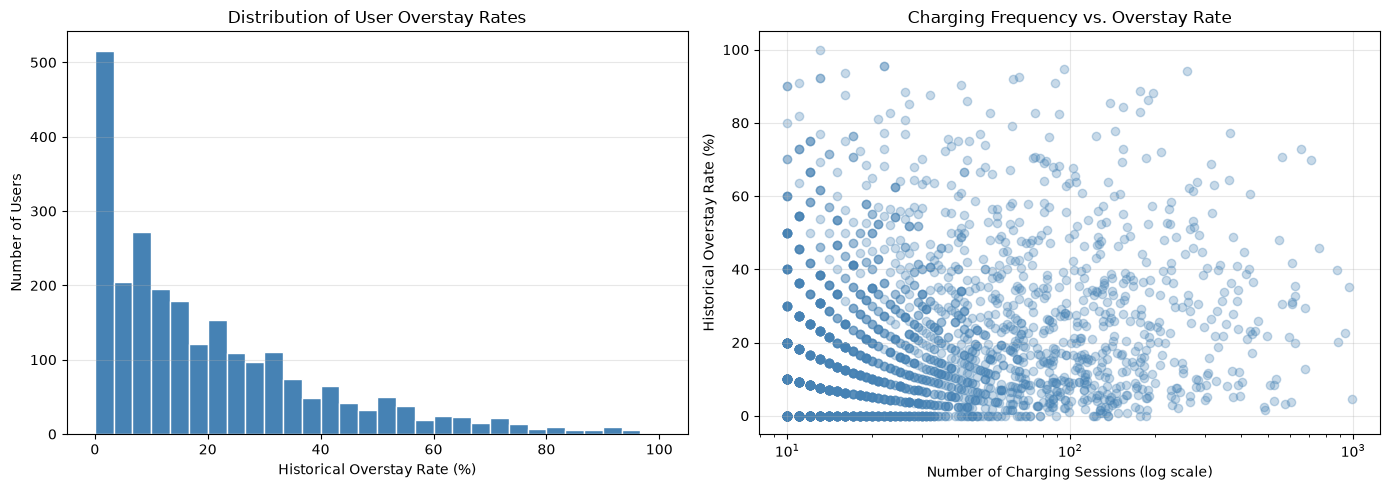

In [14]:
# Cell 16: Historical user behaviour analysis
# Use training period only
train_history = df[
    (df["Start Date"] < test_start) &
    (df["End Date"] < test_start)
].copy()

# Remove missing user IDs and invalid idle times
train_history = train_history.dropna(
    subset=["User ID", "idle_minutes"]
)

train_history = train_history[
    train_history["idle_minutes"] >= 0
].copy()

# Define overstay behaviour using the selected threshold
train_history["is_excessive_overstay"] = (
    train_history["idle_minutes"] > OVERSTAY_THRESHOLD_MINS
).astype(int)

# Aggregate historical user behaviour
user_history = (
    train_history
    .groupby("User ID", as_index=False)
    .agg(
        total_sessions=("idle_minutes", "count"),
        overstay_sessions=("is_excessive_overstay", "sum"),
        overstay_rate=("is_excessive_overstay", "mean"),
        mean_idle_minutes=("idle_minutes", "mean")
    )
)

# Focus on users with sufficient charging history
MIN_SESSIONS = 10

frequent_users = user_history[
    user_history["total_sessions"] >= MIN_SESSIONS
].copy()

print("Total historical users:", len(user_history))
print("Users with at least 10 sessions:", len(frequent_users))

print("\nHistorical user behaviour:")
display(frequent_users.describe().round(3))

# Visualize historical overstay behaviour
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    frequent_users["overstay_rate"] * 100,
    bins=30,
    color="steelblue",
    edgecolor="white"
)

axes[0].set_title("Distribution of User Overstay Rates")
axes[0].set_xlabel("Historical Overstay Rate (%)")
axes[0].set_ylabel("Number of Users")
axes[0].grid(axis="y", alpha=0.3)

axes[1].scatter(
    frequent_users["total_sessions"],
    frequent_users["overstay_rate"] * 100,
    alpha=0.3,
    color="steelblue"
)

axes[1].set_xscale("log")
axes[1].set_title("Charging Frequency vs. Overstay Rate")
axes[1].set_xlabel("Number of Charging Sessions (log scale)")
axes[1].set_ylabel("Historical Overstay Rate (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Cell 17: Historical feature engineering
# Prepare extended dataset
extended_df = df.copy()

extended_df = extended_df.dropna(
    subset=["Start Date", "End Date", "idle_minutes"]
)

extended_df = extended_df[
    (extended_df["idle_minutes"] >= 0) &
    (extended_df["End Date"] >= extended_df["Start Date"])
].copy()

# Define target consistently
extended_df["is_excessive_overstay"] = (
    extended_df["idle_minutes"] > OVERSTAY_THRESHOLD_MINS
).astype(int)

# Generate temporal features
extended_df["start_hour"] = extended_df["Start Date"].dt.hour
extended_df["day_of_week_num"] = extended_df["Start Date"].dt.dayofweek
extended_df["month"] = extended_df["Start Date"].dt.month

extended_df["is_weekend"] = (
    extended_df["day_of_week_num"] >= 5
).astype(int)

# Chronological ordering
extended_df = extended_df.sort_values(
    "Start Date"
).reset_index(drop=True)

# Unique identifier for each session
extended_df["session_id"] = np.arange(len(extended_df))


# Function to calculate historical features
def calculate_history(data, group_col, prefix):

    history = data.dropna(subset=[group_col]).copy()

    history = history.sort_values(
        ["End Date", "session_id"]
    )

    # Cumulative statistics based on completed sessions
    history[f"{prefix}_sessions"] = (
        history.groupby(group_col).cumcount() + 1
    )

    history[f"{prefix}_overstay_rate"] = (
        history.groupby(group_col)["is_excessive_overstay"]
        .cumsum() / history[f"{prefix}_sessions"]
    )

    history[f"{prefix}_mean_idle"] = (
        history.groupby(group_col)["idle_minutes"]
        .cumsum() / history[f"{prefix}_sessions"]
    )

    # Keep historical statistics
    history = history[[
        group_col,
        "End Date",
        f"{prefix}_sessions",
        f"{prefix}_overstay_rate",
        f"{prefix}_mean_idle"
    ]].rename(columns={
        "End Date": f"{prefix}_last_end"
    })

    # Current charging sessions
    current = data.dropna(subset=[group_col])[[
        "session_id",
        group_col,
        "Start Date"
    ]].copy()

    # Match each session to the most recent completed session
    matched = pd.merge_asof(
        current.sort_values("Start Date"),
        history.sort_values(f"{prefix}_last_end"),
        left_on="Start Date",
        right_on=f"{prefix}_last_end",
        by=group_col,
        direction="backward",
        allow_exact_matches=False
    )

    # Time since last completed session
    matched[f"{prefix}_hours_since_last"] = (
        matched["Start Date"] -
        matched[f"{prefix}_last_end"]
    ).dt.total_seconds() / 3600

    return matched[[
        "session_id",
        f"{prefix}_sessions",
        f"{prefix}_overstay_rate",
        f"{prefix}_mean_idle",
        f"{prefix}_hours_since_last"
    ]]


# Calculate historical user behaviour
user_features = calculate_history(
    extended_df,
    group_col="User ID",
    prefix="hist_user"
)

# Calculate historical station behaviour
station_features = calculate_history(
    extended_df,
    group_col="Station Name",
    prefix="hist_station"
)

# Merge historical features into dataset
extended_df = extended_df.merge(
    user_features,
    on="session_id",
    how="left"
)

extended_df = extended_df.merge(
    station_features,
    on="session_id",
    how="left"
)

# Select historical features
historical_features = [
    "hist_user_sessions",
    "hist_user_overstay_rate",
    "hist_user_mean_idle",
    "hist_station_overstay_rate",
    "hist_user_hours_since_last"
]

print("Extended dataset shape:", extended_df.shape)

print("\nHistorical feature statistics:")
display(extended_df[historical_features].describe().round(3))

print("\nMissing historical feature values (%):")
display(
    (extended_df[historical_features].isna().mean() * 100)
    .round(2)
)

print("\nExample historical features:")
display(
    extended_df[
        ["User ID", "Start Date"] + historical_features
    ].head(15)
)

C:\Users\harja\AppData\Local\Temp\ipykernel_21660\3603822711.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  extended_df["day_of_week_num"] = extended_df["Start Date"].dt.dayofweek


Extended dataset shape: (253396, 54)

Historical feature statistics:


,hist_user_sessions,hist_user_overstay_rate,hist_user_mean_idle,hist_station_overstay_rate,hist_user_hours_since_last
count,224567.000,224567.000,224567.000,253345.000,224567.000
mean,97.108,0.210,29.708,0.230,776.548
std,143.814,0.227,49.845,0.050,2726.357
min,1.000,0.000,0.000,0.000,0.017
25%,10.000,0.016,3.680,0.196,21.917
50%,39.000,0.136,13.531,0.226,75.633
75%,119.000,0.333,32.819,0.257,332.967
max,1097.000,1.000,817.950,1.000,65342.733



Missing historical feature values (%):


hist_user_sessions            11.38
hist_user_overstay_rate       11.38
hist_user_mean_idle           11.38
hist_station_overstay_rate     0.02
hist_user_hours_since_last    11.38
dtype: float64


Example historical features:


,User ID,Start Date,hist_user_sessions,hist_user_overstay_rate,hist_user_mean_idle,hist_station_overstay_rate,hist_user_hours_since_last
0,3284,2011-07-29 20:17:00,NaN,NaN,NaN,NaN,NaN
1,4169,2011-07-30 00:00:00,NaN,NaN,NaN,1.000000,NaN
2,4169,2011-07-30 08:16:00,1.0,0.0,0.200000,0.500000,8.233333
3,2545,2011-07-30 14:51:00,NaN,NaN,NaN,0.333333,NaN
4,3765,2011-07-30 18:51:00,NaN,NaN,NaN,0.250000,NaN
5,5144,2011-07-30 21:38:00,NaN,NaN,NaN,0.200000,NaN
6,4447,2011-07-31 04:33:00,NaN,NaN,NaN,0.333333,NaN
7,4169,2011-07-31 12:25:00,2.0,0.0,0.133333,0.428571,23.850000
8,4447,2011-07-31 17:41:00,1.0,1.0,69.533333,0.375000,7.016667
9,4440,2011-08-01 19:11:00,NaN,NaN,NaN,0.333333,NaN


In [16]:
# Cell 18: Extended feature selection and chronological split
# Indicate whether historical user information is available
extended_df["has_user_history"] = (
    extended_df["hist_user_sessions"].notna()
).astype(int)

# Users without history have zero previously recorded sessions
extended_df["hist_user_sessions"] = (
    extended_df["hist_user_sessions"].fillna(0)
)

# Combine original and historical features
extended_features = features + historical_features + [
    "has_user_history"
]

# Prepare extended modelling dataset
extended_model_df = extended_df[
    extended_features + [
        target,
        "Start Date",
        "End Date",
        "idle_minutes"
    ]
].dropna(
    subset=features + [target, "Start Date", "End Date"]
).copy()

extended_model_df = extended_model_df.sort_values(
    "Start Date"
).reset_index(drop=True)

# Preserve original chronological test boundary
train_mask = (
    (extended_model_df["Start Date"] < test_start) &
    (extended_model_df["End Date"] < test_start)
)

test_mask = (
    extended_model_df["Start Date"] >= test_start
)

# Extended training and test sets
X_train_extended = extended_model_df.loc[
    train_mask, extended_features
].copy()

X_test_extended = extended_model_df.loc[
    test_mask, extended_features
].copy()

y_train_extended = extended_model_df.loc[
    train_mask, target
].copy()

y_test_extended = extended_model_df.loc[
    test_mask, target
].copy()

print("Number of features:", len(extended_features))
print("Extended training set:", X_train_extended.shape)
print("Extended test set:", X_test_extended.shape)

print("\nTraining target distribution:")
print(y_train_extended.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test_extended.value_counts(normalize=True))

print("\nOriginal test boundary:", test_start)

Number of features: 12
Extended training set: (177368, 12)
Extended test set: (76019, 12)

Training target distribution:
is_excessive_overstay
0    0.770443
1    0.229557
Name: proportion, dtype: float64

Test target distribution:
is_excessive_overstay
0    0.856049
1    0.143951
Name: proportion, dtype: float64

Original test boundary: 2018-10-21 17:33:00


In [17]:
# Cell 19: Preprocessing for extended models
extended_numerical_features = historical_features

extended_binary_features = [
    "is_weekend",
    "has_user_history"
]

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Extended preprocessing pipeline
extended_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            extended_numerical_features
        ),
        (
            "binary",
            "passthrough",
            extended_binary_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [18]:
# Cell 20: Chronological validation split
validation_idx = int(len(X_train_extended) * 0.8)

validation_start = extended_model_df.loc[
    X_train_extended.index[validation_idx],
    "Start Date"
]

# Exclude sessions whose outcomes are unavailable
# at the beginning of the validation period
dev_train_mask = (
    extended_model_df.loc[
        X_train_extended.index, "Start Date"
    ] < validation_start
) & (
    extended_model_df.loc[
        X_train_extended.index, "End Date"
    ] < validation_start
)

val_mask = (
    extended_model_df.loc[
        X_train_extended.index, "Start Date"
    ] >= validation_start
)

X_dev = X_train_extended.loc[dev_train_mask].copy()
y_dev = y_train_extended.loc[dev_train_mask].copy()

X_val = X_train_extended.loc[val_mask].copy()
y_val = y_train_extended.loc[val_mask].copy()

print("Development training set:", X_dev.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test_extended.shape)

print("\nValidation boundary:", validation_start)

print("\nDevelopment target distribution:")
print(y_dev.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Development training set: (141879, 12)
Validation set: (35474, 12)
Final test set: (76019, 12)

Validation boundary: 2017-12-19 16:27:00

Development target distribution:
is_excessive_overstay
0    0.757681
1    0.242319
Name: proportion, dtype: float64

Validation target distribution:
is_excessive_overstay
0    0.821475
1    0.178525
Name: proportion, dtype: float64


In [19]:
# Cell 21: Compare basic and extended feature sets
feature_sets = {
    "Basic": {
        "features": features,
        "preprocessor": preprocessor
    },

    "Extended": {
        "features": extended_features,
        "preprocessor": extended_preprocessor
    }
}

comparison_results = []
validation_models = {}

for feature_set, config in feature_sets.items():

    selected_features = config["features"]

    for name, model in models.items():

        print(f"Training {feature_set} - {name}...")

        start_time = time.time()

        pipeline = Pipeline([
            (
                "preprocessing",
                clone(config["preprocessor"])
            ),
            (
                "classifier",
                clone(model)
            )
        ])

        # Train model
        pipeline.fit(
            X_dev[selected_features],
            y_dev
        )

        training_time = time.time() - start_time

        # Validation predictions
        y_pred = pipeline.predict(
            X_val[selected_features]
        )

        y_prob = pipeline.predict_proba(
            X_val[selected_features]
        )[:, 1]

        # Store trained model
        validation_models[(feature_set, name)] = pipeline

        # Evaluate performance
        comparison_results.append({
            "Feature Set": feature_set,
            "Model": name,

            "Accuracy": accuracy_score(y_val, y_pred),

            "Balanced Accuracy": balanced_accuracy_score(
                y_val, y_pred
            ),

            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),

            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),

            "F1-score": f1_score(
                y_val, y_pred, zero_division=0
            ),

            "ROC-AUC": roc_auc_score(
                y_val, y_prob
            ),

            "Average Precision": average_precision_score(
                y_val, y_prob
            ),

            "Training time (s)": training_time
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

Training Basic - Baseline...
Training Basic - Logistic Regression...
Training Basic - Decision Tree...
Training Basic - Random Forest...
Training Extended - Baseline...
Training Extended - Logistic Regression...
Training Extended - Decision Tree...
Training Extended - Random Forest...


,Feature Set,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Training time (s)
0,Basic,Baseline,0.8215,0.5000,0.0000,0.0000,0.0000,0.5000,0.1785,0.0702
1,Basic,Logistic Regression,0.5934,0.5268,0.1993,0.4232,0.2709,0.5338,0.1976,0.3133
2,Basic,Decision Tree,0.6991,0.4995,0.1778,0.1890,0.1832,0.5014,0.1836,0.2828
3,Basic,Random Forest,0.6723,0.5214,0.2035,0.2868,0.2380,0.5489,0.2018,1.8343
4,Extended,Baseline,0.8215,0.5000,0.0000,0.0000,0.0000,0.5000,0.1785,0.1522
5,Extended,Logistic Regression,0.7440,0.6573,0.3533,0.5223,0.4215,0.7143,0.3745,0.5316
6,Extended,Decision Tree,0.7326,0.6667,0.3470,0.5642,0.4297,0.7312,0.3946,1.8814
7,Extended,Random Forest,0.7327,0.6667,0.3471,0.5640,0.4297,0.7356,0.4022,8.3325


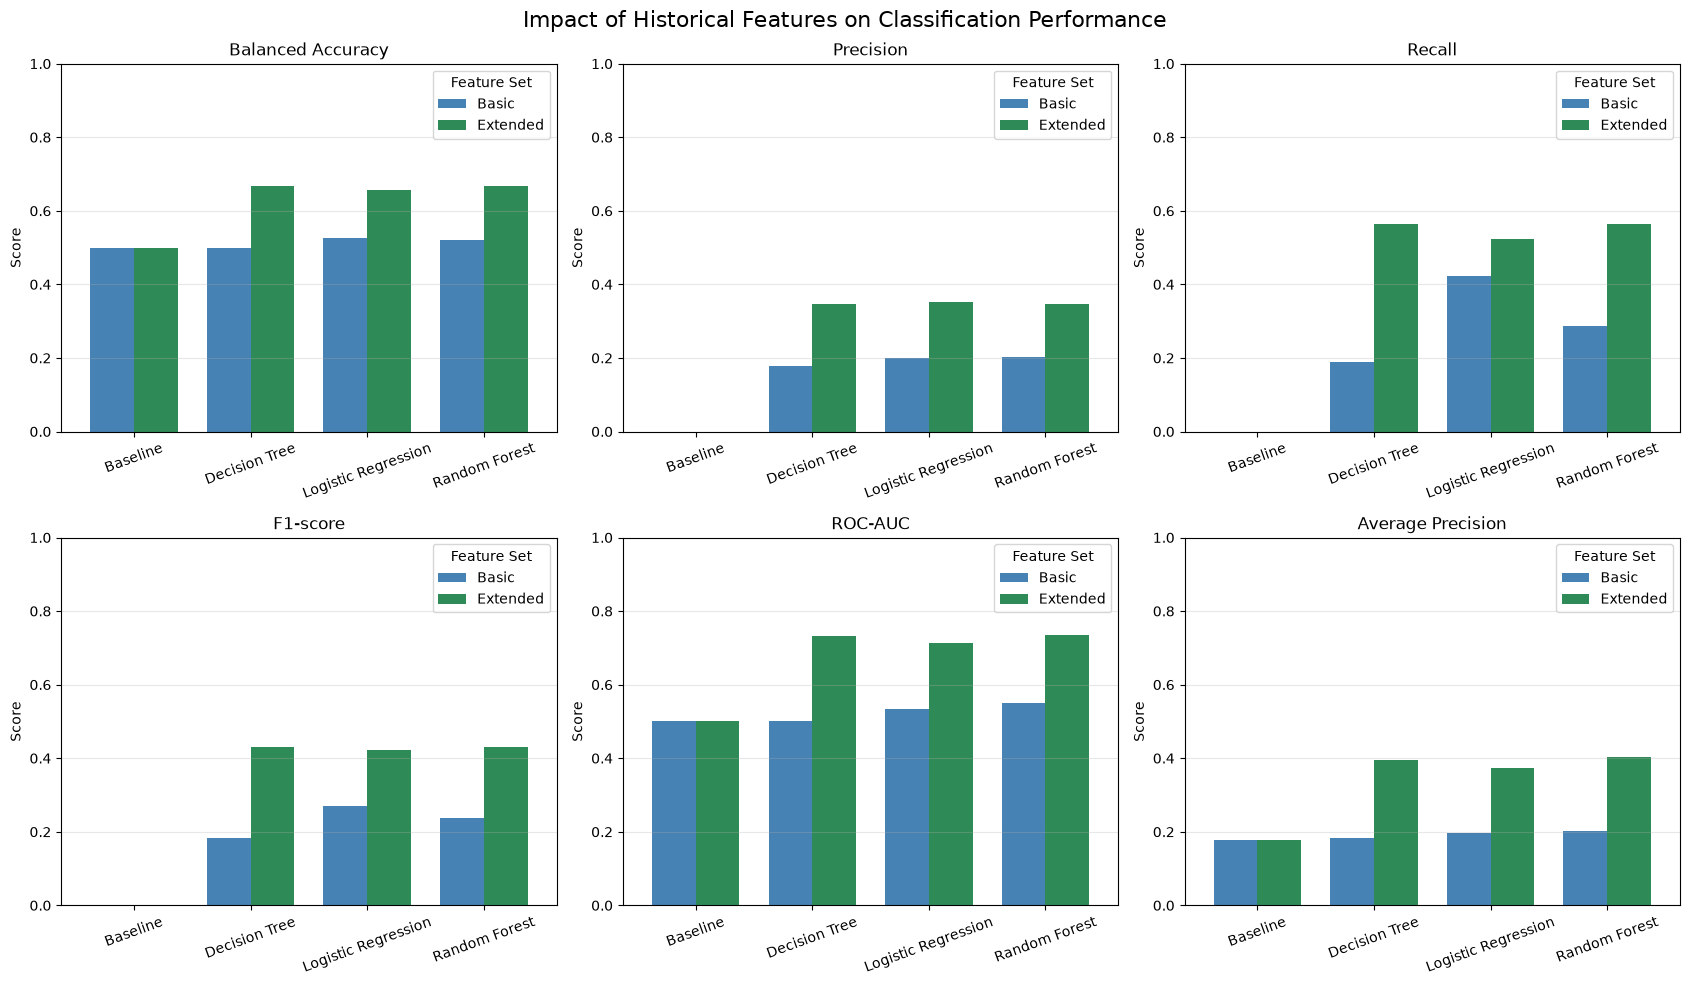

In [20]:
# Cell 22: Basic vs extended feature comparison
comparison_metrics = [
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, metric in zip(axes.ravel(), comparison_metrics):

    pivot_df = comparison_df.pivot(
        index="Model",
        columns="Feature Set",
        values=metric
    )

    pivot_df.plot(
        kind="bar",
        ax=ax,
        color=["steelblue", "seagreen"],
        width=0.75
    )

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Impact of Historical Features on Classification Performance",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [21]:
# Cell 23: Quantify performance improvements
improvement_df = (
    comparison_df.pivot(
        index="Model",
        columns="Feature Set",
        values=[
            "ROC-AUC",
            "F1-score",
            "Average Precision"
        ]
    )
)

improvements = pd.DataFrame({
    metric: (
        improvement_df[(metric, "Extended")] -
        improvement_df[(metric, "Basic")]
    )
    for metric in [
        "ROC-AUC",
        "F1-score",
        "Average Precision"
    ]
})

display(improvements.round(4))

,ROC-AUC,F1-score,Average Precision
Model,,,
Baseline,0.0000,0.0000,0.0000
Decision Tree,0.2298,0.2465,0.2109
Logistic Regression,0.1805,0.1505,0.1770
Random Forest,0.1867,0.1917,0.2003


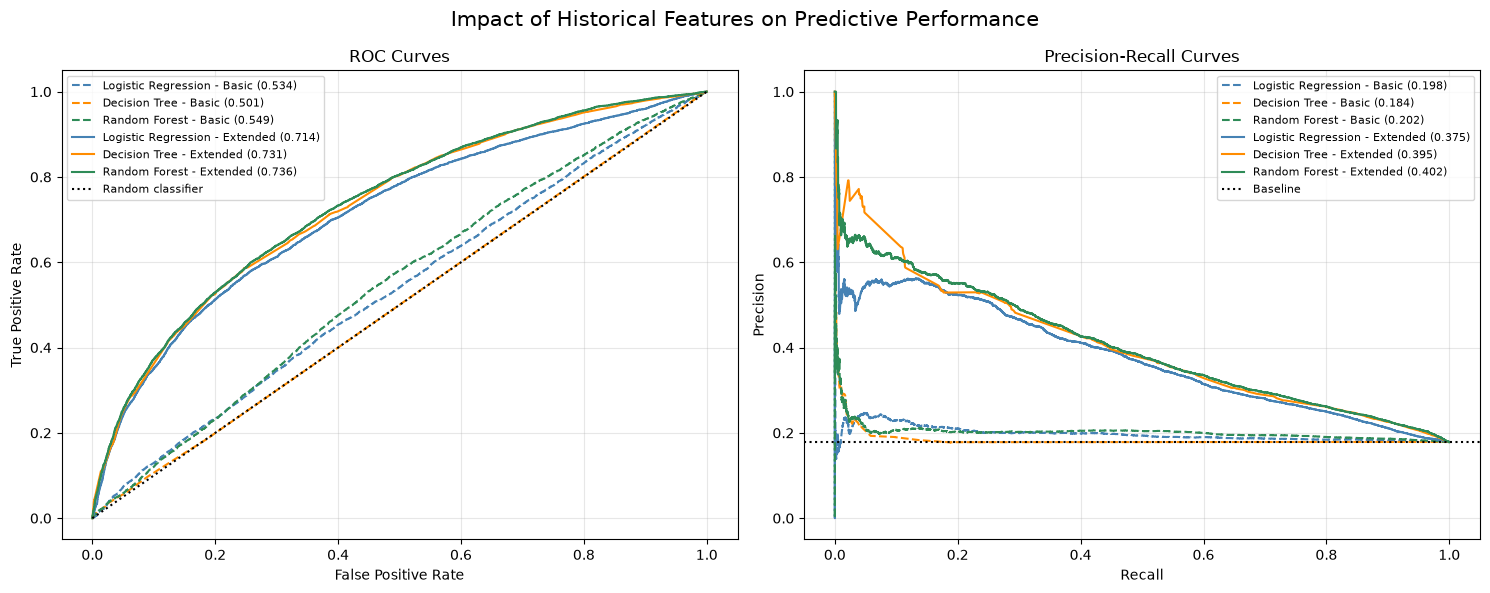

In [22]:
# Cell 24: ROC and precision-recall comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

model_colors = {
    "Logistic Regression": "steelblue",
    "Decision Tree": "darkorange",
    "Random Forest": "seagreen"
}

for feature_set, config in feature_sets.items():

    selected_features = config["features"]

    linestyle = "--" if feature_set == "Basic" else "-"

    for name in model_colors:

        pipeline = validation_models[(feature_set, name)]

        y_prob = pipeline.predict_proba(
            X_val[selected_features]
        )[:, 1]

        # ROC curve
        fpr, tpr, _ = roc_curve(y_val, y_prob)
        auc_score = roc_auc_score(y_val, y_prob)

        axes[0].plot(
            fpr,
            tpr,
            color=model_colors[name],
            linestyle=linestyle,
            label=f"{name} - {feature_set} ({auc_score:.3f})"
        )

        # Precision-recall curve
        precision, recall, _ = precision_recall_curve(
            y_val, y_prob
        )

        ap_score = average_precision_score(y_val, y_prob)

        axes[1].plot(
            recall,
            precision,
            color=model_colors[name],
            linestyle=linestyle,
            label=f"{name} - {feature_set} ({ap_score:.3f})"
        )

# ROC baseline
axes[0].plot(
    [0, 1], [0, 1],
    linestyle=":",
    color="black",
    label="Random classifier"
)

axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Precision-recall baseline
axes[1].axhline(
    y=y_val.mean(),
    linestyle=":",
    color="black",
    label="Baseline"
)

axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Impact of Historical Features on Predictive Performance",
    fontsize=15
)

plt.tight_layout()
plt.show()

Calculating feature importance for Logistic Regression...
Calculating feature importance for Decision Tree...
Calculating feature importance for Random Forest...


,Feature,Importance,Std
7,hist_user_overstay_rate,0.0734,0.0017
8,hist_user_mean_idle,0.0567,0.0013
6,hist_user_sessions,0.0082,0.0002
10,hist_user_hours_since_last,0.0044,0.0004
0,start_hour,0.0024,0.0003
1,day_of_week_num,0.0008,0.0001
3,is_weekend,0.0006,0.0001
9,hist_station_overstay_rate,0.0005,0.0001
11,has_user_history,0.0003,0.0001
4,Station Name,0.0003,0.0001


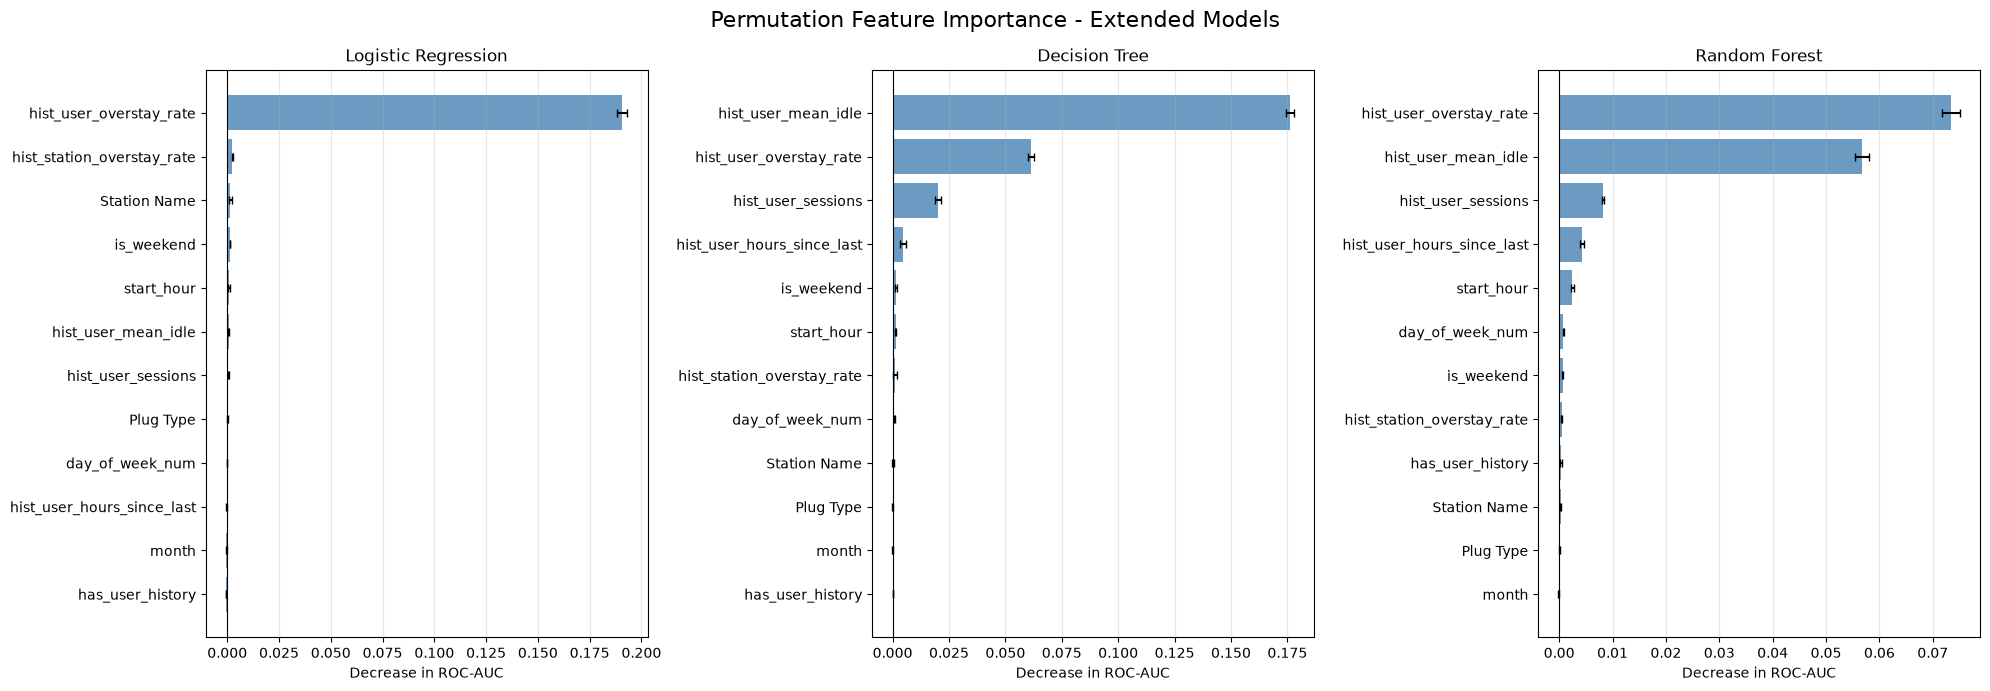

In [23]:
# Cell 25: Permutation feature importance
importance_results = {}
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

for name in model_names:

    print(f"Calculating feature importance for {name}...")

    pipeline = validation_models[("Extended", name)]

    importance = permutation_importance(
        pipeline,
        X_val[extended_features],
        y_val,
        scoring="roc_auc",
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )

    importance_results[name] = pd.DataFrame({
        "Feature": extended_features,
        "Importance": importance.importances_mean,
        "Std": importance.importances_std
    }).sort_values("Importance", ascending=False)

# Display Random Forest feature importance
display(
    importance_results["Random Forest"].round(4)
)

# Visualize feature importance for all three models
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, name in zip(axes, model_names):

    importance_df = importance_results[name].sort_values(
        "Importance"
    )

    ax.barh(
        importance_df["Feature"],
        importance_df["Importance"],
        xerr=importance_df["Std"],
        color="steelblue",
        alpha=0.8,
        capsize=3
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Decrease in ROC-AUC")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "Permutation Feature Importance - Extended Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [24]:
# Cell 26: Classification decision-threshold optimization
decision_thresholds = np.linspace(0.05, 0.95, 91)

threshold_performance = []

for name in model_names:

    pipeline = validation_models[("Extended", name)]

    y_prob = pipeline.predict_proba(
        X_val[extended_features]
    )[:, 1]

    for threshold in decision_thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        threshold_performance.append({
            "Model": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(
                y_val, y_pred
            ),
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, y_pred, zero_division=0
            )
        })

decision_threshold_df = pd.DataFrame(
    threshold_performance
)

# Select the best threshold for each model using F1-score
best_thresholds = decision_threshold_df.loc[
    decision_threshold_df.groupby("Model")["F1-score"].idxmax()
].set_index("Model")

print("Best decision thresholds based on validation F1-score:")

display(best_thresholds.round(4))

Best decision thresholds based on validation F1-score:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
Model,,,,,,
Decision Tree,0.53,0.7500,0.6651,0.3635,0.5329,0.4322
Logistic Regression,0.52,0.7562,0.6553,0.3658,0.4983,0.4219
Random Forest,0.55,0.7595,0.6633,0.3737,0.5138,0.4327


In [25]:
# Cell 28: Final model training
final_models = {}

for feature_set, config in feature_sets.items():

    selected_features = config["features"]

    for name, model in models.items():

        print(f"Training final {feature_set} - {name}...")

        pipeline = Pipeline([
            (
                "preprocessing",
                clone(config["preprocessor"])
            ),
            (
                "classifier",
                clone(model)
            )
        ])

        # Train on the complete eligible training dataset
        pipeline.fit(
            X_train_extended[selected_features],
            y_train_extended
        )

        # Store final trained model
        final_models[(feature_set, name)] = pipeline

print("\nAll final models trained successfully.")

Training final Basic - Baseline...
Training final Basic - Logistic Regression...
Training final Basic - Decision Tree...
Training final Basic - Random Forest...
Training final Extended - Baseline...
Training final Extended - Logistic Regression...
Training final Extended - Decision Tree...
Training final Extended - Random Forest...

All final models trained successfully.


In [26]:
# Cell 29: Final test-set evaluation
final_results = []
final_predictions = {}
final_probabilities = {}

for feature_set, config in feature_sets.items():

    selected_features = config["features"]

    for name in models:

        pipeline = final_models[(feature_set, name)]

        # Predict scores on the test dataset
        y_prob = pipeline.predict_proba(
            X_test_extended[selected_features]
        )[:, 1]

        final_probabilities[(feature_set, name)] = y_prob

        # Default classification threshold
        thresholds_to_evaluate = {
            "Default": 0.5
        }

        # Add optimized threshold for extended models
        if feature_set == "Extended" and name in best_thresholds.index:

            thresholds_to_evaluate["Optimized"] = (
                best_thresholds.loc[name, "Threshold"]
            )

        for threshold_type, threshold in thresholds_to_evaluate.items():

            y_pred = (y_prob >= threshold).astype(int)

            final_predictions[
                (feature_set, name, threshold_type)
            ] = y_pred

            final_results.append({
                "Feature Set": feature_set,
                "Model": name,
                "Threshold Type": threshold_type,
                "Threshold": threshold,

                "Accuracy": accuracy_score(
                    y_test_extended, y_pred
                ),

                "Balanced Accuracy": balanced_accuracy_score(
                    y_test_extended, y_pred
                ),

                "Precision": precision_score(
                    y_test_extended, y_pred, zero_division=0
                ),

                "Recall": recall_score(
                    y_test_extended, y_pred, zero_division=0
                ),

                "F1-score": f1_score(
                    y_test_extended, y_pred, zero_division=0
                ),

                "ROC-AUC": roc_auc_score(
                    y_test_extended, y_prob
                ),

                "Average Precision": average_precision_score(
                    y_test_extended, y_prob
                )
            })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Feature Set,Model,Threshold Type,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Basic,Baseline,Default,0.50,0.8560,0.5000,0.0000,0.0000,0.0000,0.5000,0.1440
1,Basic,Logistic Regression,Default,0.50,0.6691,0.5344,0.1735,0.3452,0.2309,0.5549,0.1759
2,Basic,Decision Tree,Default,0.50,0.8042,0.5139,0.1855,0.1063,0.1351,0.5507,0.1677
3,Basic,Random Forest,Default,0.50,0.6280,0.5447,0.1753,0.4278,0.2487,0.5746,0.1827
4,Extended,Baseline,Default,0.50,0.8560,0.5000,0.0000,0.0000,0.0000,0.5000,0.1440
5,Extended,Logistic Regression,Default,0.50,0.8081,0.6757,0.3731,0.4898,0.4235,0.7532,0.3713
6,Extended,Logistic Regression,Optimized,0.52,0.8167,0.6697,0.3860,0.4632,0.4211,0.7532,0.3713
7,Extended,Decision Tree,Default,0.50,0.7813,0.6812,0.3377,0.5406,0.4157,0.7551,0.3830
8,Extended,Decision Tree,Optimized,0.53,0.7958,0.6738,0.3530,0.5025,0.4147,0.7551,0.3830
9,Extended,Random Forest,Default,0.50,0.7853,0.6913,0.3474,0.5592,0.4286,0.7731,0.4103


In [27]:
# Cell 32: Random Forest hyperparameter tuning
# Combine development and validation sets
X_search = pd.concat([X_dev, X_val])
y_search = pd.concat([y_dev, y_val])

# Preserve chronological validation split
test_fold = np.concatenate([
    np.full(len(X_dev), -1),
    np.zeros(len(X_val), dtype=int)
])

cv_split = PredefinedSplit(test_fold)

# Define Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessing", clone(extended_preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [8, 15, 25, None],
    "classifier__min_samples_leaf": [5, 10, 20, 50],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "classifier__class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}

# Randomized hyperparameter search
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring={
        "ROC-AUC": "roc_auc",
        "Average Precision": "average_precision",
        "F1": "f1"
    },
    refit=False,
    cv=cv_split,
    random_state=42,
    n_jobs=1,
    verbose=2
)

# Run hyperparameter search
rf_search.fit(X_search, y_search)

# Store search results
rf_search_results = pd.DataFrame(
    rf_search.cv_results_
).sort_values(
    "mean_test_Average Precision",
    ascending=False
)

display(
    rf_search_results[[
        "params",
        "mean_test_ROC-AUC",
        "mean_test_Average Precision",
        "mean_test_F1",
        "mean_fit_time"
    ]].head(10)
)

# Extract best parameters based on Average Precision
best_rf_params = rf_search_results.iloc[0]["params"]

print("\nBest Random Forest parameters:")
for param, value in best_rf_params.items():
    print(f"{param}: {value}")

Fitting 1 folds for each of 20 candidates, totalling 20 fits
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=log2, classifier__min_samples_leaf=20, classifier__min_samples_split=10, classifier__n_estimators=200; total time=  12.1s
[CV] END classifier__class_weight=None, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_leaf=20, classifier__min_samples_split=10, classifier__n_estimators=200; total time=  48.6s
[CV] END classifier__class_weight=balanced, classifier__max_depth=25, classifier__max_features=0.5, classifier__min_samples_leaf=20, classifier__min_samples_split=20, classifier__n_estimators=200; total time= 2.9min
[CV] END classifier__class_weight=balanced_subsample, classifier__max_depth=15, classifier__max_features=log2, classifier__min_samples_leaf=20, classifier__min_samples_split=10, classifier__n_estimators=100; total time=   8.4s
[CV] END classifier__class_weight=balanced_subsample, classifier

,params,mean_test_ROC-AUC,mean_test_Average Precision,mean_test_F1,mean_fit_time
2,"{'classifier__n_estimators': 200, 'classifier_...",0.742273,0.420602,0.439781,171.249692
7,"{'classifier__n_estimators': 200, 'classifier_...",0.742768,0.418863,0.436972,111.626520
10,"{'classifier__n_estimators': 200, 'classifier_...",0.739480,0.416968,0.436656,206.685616
17,"{'classifier__n_estimators': 300, 'classifier_...",0.739492,0.416750,0.437311,321.460579
1,"{'classifier__n_estimators': 200, 'classifier_...",0.739048,0.412439,0.252927,48.101464
19,"{'classifier__n_estimators': 100, 'classifier_...",0.736918,0.412262,0.252535,33.462729
9,"{'classifier__n_estimators': 200, 'classifier_...",0.739192,0.411209,0.275821,28.771466
12,"{'classifier__n_estimators': 200, 'classifier_...",0.736961,0.411167,0.435335,244.981763
4,"{'classifier__n_estimators': 100, 'classifier_...",0.736326,0.410905,0.430765,119.236503
18,"{'classifier__n_estimators': 200, 'classifier_...",0.739876,0.410655,0.434967,38.458849



Best Random Forest parameters:
classifier__n_estimators: 200
classifier__min_samples_split: 20
classifier__min_samples_leaf: 20
classifier__max_features: 0.5
classifier__max_depth: 25
classifier__class_weight: balanced


In [28]:
# Cell 33: Evaluate tuned Random Forest on validation data
tuned_rf = clone(rf_pipeline).set_params(
    **best_rf_params
)

tuned_rf.fit(X_dev, y_dev)

y_prob_tuned = tuned_rf.predict_proba(X_val)[:, 1]

y_pred_tuned = (y_prob_tuned >= 0.5).astype(int)

tuned_results = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_val, y_pred_tuned),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_pred_tuned
    ),
    "Precision": precision_score(
        y_val, y_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_pred_tuned, zero_division=0
    ),
    "F1-score": f1_score(y_val, y_pred_tuned),
    "ROC-AUC": roc_auc_score(y_val, y_prob_tuned),
    "Average Precision": average_precision_score(
        y_val, y_prob_tuned
    )
}])

original_rf_results = comparison_df[
    (comparison_df["Feature Set"] == "Extended") &
    (comparison_df["Model"] == "Random Forest")
].copy()

original_rf_results["Model"] = "Original Random Forest"

rf_comparison = pd.concat([
    original_rf_results[tuned_results.columns],
    tuned_results
], ignore_index=True)

display(rf_comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Original Random Forest,0.7327,0.6667,0.3471,0.5640,0.4297,0.7356,0.4022
1,Tuned Random Forest,0.7494,0.6717,0.3660,0.5509,0.4398,0.7423,0.4206


In [29]:
# Cell 34: Gradient Boosting classification
# HistGradientBoosting requires dense input
gb_preprocessor = clone(extended_preprocessor)

gb_preprocessor.set_params(
    cat__sparse_output=False,
    sparse_threshold=0.0
)

# Define Gradient Boosting classifier
gb_pipeline = Pipeline([
    ("preprocessing", gb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=200,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ))
])

# Account for class imbalance
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_dev
)

# Train model
start_time = time.time()

gb_pipeline.fit(
    X_dev[extended_features],
    y_dev,
    classifier__sample_weight=sample_weights
)

gb_training_time = time.time() - start_time

# Validation predictions
y_prob_gb = gb_pipeline.predict_proba(
    X_val[extended_features]
)[:, 1]

y_pred_gb = (y_prob_gb >= 0.5).astype(int)

# Evaluate performance
gb_results = pd.DataFrame([{
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_val, y_pred_gb),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_pred_gb
    ),
    "Precision": precision_score(
        y_val, y_pred_gb, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_pred_gb, zero_division=0
    ),
    "F1-score": f1_score(y_val, y_pred_gb),
    "ROC-AUC": roc_auc_score(y_val, y_prob_gb),
    "Average Precision": average_precision_score(
        y_val, y_prob_gb
    )
}])

print("Training time:", round(gb_training_time, 2), "seconds")

display(gb_results.round(4))

Training time: 4.74 seconds


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Gradient Boosting,0.7462,0.6782,0.3654,0.5726,0.4461,0.7447,0.4245


In [30]:
# Cell 35: Recent historical user behaviour
improved_comparison = pd.concat([
    rf_comparison,
    gb_results
], ignore_index=True)

recent_history = extended_df.dropna(
    subset=["User ID"]
).copy()

recent_history = recent_history.sort_values(
    ["End Date", "session_id"]
)

# Group completed sessions by user
user_groups = recent_history.groupby("User ID")

# Recent overstay rates
recent_history["hist_overstay_last5"] = (
    user_groups["is_excessive_overstay"]
    .transform(
        lambda s: s.rolling(5, min_periods=1).mean()
    )
)

recent_history["hist_overstay_last10"] = (
    user_groups["is_excessive_overstay"]
    .transform(
        lambda s: s.rolling(10, min_periods=1).mean()
    )
)

# Recent average idle times
recent_history["hist_idle_last5"] = (
    user_groups["idle_minutes"]
    .transform(
        lambda s: s.rolling(5, min_periods=1).mean()
    )
)

recent_history["hist_idle_last10"] = (
    user_groups["idle_minutes"]
    .transform(
        lambda s: s.rolling(10, min_periods=1).mean()
    )
)

# Idle time of the most recent completed session
recent_history["hist_last_idle"] = (
    recent_history["idle_minutes"]
)

# Historical variability in idle time
recent_history["hist_idle_std"] = (
    user_groups["idle_minutes"]
    .transform(
        lambda s: s.expanding(min_periods=2).std()
    )
)

# Select recent historical features
recent_features = [
    "hist_overstay_last5",
    "hist_overstay_last10",
    "hist_idle_last5",
    "hist_idle_last10",
    "hist_last_idle",
    "hist_idle_std"
]

# Prepare completed-session history
recent_history = recent_history[
    ["User ID", "End Date"] + recent_features
].rename(columns={
    "End Date": "history_end"
})

# Prepare current sessions
current_sessions = extended_df.dropna(
    subset=["User ID"]
)[
    ["session_id", "User ID", "Start Date"]
].copy()

# Match only previously completed sessions
recent_matched = pd.merge_asof(
    current_sessions.sort_values("Start Date"),
    recent_history.sort_values(
        "history_end", kind="stable"
    ),
    left_on="Start Date",
    right_on="history_end",
    by="User ID",
    direction="backward",
    allow_exact_matches=False
)

# Merge into a new dataset
advanced_df = extended_df.merge(
    recent_matched[["session_id"] + recent_features],
    on="session_id",
    how="left"
)

print("Advanced dataset shape:", advanced_df.shape)

print("\nRecent historical feature statistics:")
display(
    advanced_df[recent_features].describe().round(3)
)

print("\nMissing values (%):")
display(
    (advanced_df[recent_features].isna().mean() * 100)
    .round(2)
)

Advanced dataset shape: (253396, 61)

Recent historical feature statistics:


,hist_overstay_last5,hist_overstay_last10,hist_idle_last5,hist_idle_last10,hist_last_idle,hist_idle_std
count,224567.000,224567.000,224567.000,224567.000,224567.000,212686.000
mean,0.209,0.209,29.802,29.689,30.063,42.973
std,0.275,0.254,60.940,56.972,84.411,54.507
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.492,1.490,0.233,10.907
50%,0.000,0.100,9.430,11.088,0.450,24.633
75%,0.400,0.300,30.193,31.212,22.567,51.298
max,1.000,1.000,904.890,830.923,1344.033,613.067



Missing values (%):


hist_overstay_last5     11.38
hist_overstay_last10    11.38
hist_idle_last5         11.38
hist_idle_last10        11.38
hist_last_idle          11.38
hist_idle_std           16.07
dtype: float64

In [34]:
# Cell 36: Advanced feature selection
advanced_features = extended_features + recent_features

# Reconstruct the original extended dataset with session IDs
alignment_df = extended_df[
    ["session_id"] + list(extended_model_df.columns)
].dropna(
    subset=features + [target, "Start Date", "End Date"]
).copy()

# Use the same sorting method as in Cell 18
alignment_df = alignment_df.sort_values(
    "Start Date"
).reset_index(drop=True)

# Verify that the original ordering has been recovered
pd.testing.assert_frame_equal(
    alignment_df[extended_model_df.columns],
    extended_model_df,
    check_dtype=False
)

# Match recent features using unique session IDs
advanced_model_df = alignment_df.merge(
    advanced_df[["session_id"] + recent_features],
    on="session_id",
    how="left",
    sort=False,
    validate="one_to_one"
)

# Verify alignment after merging
pd.testing.assert_frame_equal(
    advanced_model_df[extended_model_df.columns],
    extended_model_df,
    check_dtype=False
)

# Preserve existing development, validation and test observations
X_dev_advanced = advanced_model_df.loc[
    X_dev.index, advanced_features
].copy()

X_val_advanced = advanced_model_df.loc[
    X_val.index, advanced_features
].copy()

X_train_advanced = advanced_model_df.loc[
    X_train_extended.index, advanced_features
].copy()

X_test_advanced = advanced_model_df.loc[
    X_test_extended.index, advanced_features
].copy()

# Verify target alignment
assert advanced_model_df.loc[X_dev.index, target].equals(y_dev)
assert advanced_model_df.loc[X_val.index, target].equals(y_val)
assert advanced_model_df.loc[X_test_extended.index, target].equals(
    y_test_extended
)

print("Dataset alignment successful!")

print("\nNumber of predictors:", len(advanced_features))
print("Development set:", X_dev_advanced.shape)
print("Validation set:", X_val_advanced.shape)
print("Training set:", X_train_advanced.shape)
print("Test set:", X_test_advanced.shape)

Dataset alignment successful!

Number of predictors: 18
Development set: (141879, 18)
Validation set: (35474, 18)
Training set: (177368, 18)
Test set: (76019, 18)


In [35]:
# Cell 37: Advanced preprocessing
advanced_numerical_features = (
    historical_features + recent_features
)

advanced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            advanced_numerical_features
        ),
        (
            "binary",
            "passthrough",
            extended_binary_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    sparse_threshold=0.0
)

In [36]:
# Cell 38: Gradient Boosting with advanced features
advanced_gb = Pipeline([
    ("preprocessing", clone(advanced_preprocessor)),
    ("classifier", clone(
        gb_pipeline.named_steps["classifier"]
    ))
])

# Account for class imbalance
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_dev
)

# Train advanced model
start_time = time.time()

advanced_gb.fit(
    X_dev_advanced,
    y_dev,
    classifier__sample_weight=sample_weights
)

advanced_training_time = time.time() - start_time

# Validation predictions
y_prob_advanced = advanced_gb.predict_proba(
    X_val_advanced
)[:, 1]

y_pred_advanced = (
    y_prob_advanced >= 0.5
).astype(int)

# Evaluate performance
advanced_results = pd.DataFrame([{
    "Model": "Advanced Gradient Boosting",
    "Accuracy": accuracy_score(y_val, y_pred_advanced),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_pred_advanced
    ),
    "Precision": precision_score(
        y_val, y_pred_advanced, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_pred_advanced
    ),
    "F1-score": f1_score(
        y_val, y_pred_advanced
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_prob_advanced
    ),
    "Average Precision": average_precision_score(
        y_val, y_prob_advanced
    )
}])

print(
    "Training time:",
    round(advanced_training_time, 2),
    "seconds"
)

display(advanced_results.round(4))

Training time: 6.98 seconds


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Advanced Gradient Boosting,0.7716,0.6864,0.3992,0.5539,0.464,0.7637,0.4648


In [37]:
# Cell 39: Advanced Gradient Boosting hyperparameter tuning
# Combine development and validation datasets
X_search_advanced = pd.concat([
    X_dev_advanced,
    X_val_advanced
])

y_search_advanced = pd.concat([
    y_dev,
    y_val
])

# Preserve chronological validation split
test_fold_advanced = np.concatenate([
    np.full(len(X_dev_advanced), -1),
    np.zeros(len(X_val_advanced), dtype=int)
])

cv_advanced = PredefinedSplit(test_fold_advanced)

# Define pipeline
advanced_gb_pipeline = clone(advanced_gb)

# Class weights calculated internally from training observations
advanced_gb_pipeline.set_params(
    classifier__class_weight="balanced"
)

# Define hyperparameter search space
gb_param_distributions = {
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_iter": [100, 200, 300],
    "classifier__max_leaf_nodes": [15, 31, 63],
    "classifier__min_samples_leaf": [20, 50, 100],
    "classifier__l2_regularization": [0.1, 1.0, 5.0, 10.0]
}

# Randomized search
gb_search = RandomizedSearchCV(
    estimator=advanced_gb_pipeline,
    param_distributions=gb_param_distributions,
    n_iter=15,
    scoring={
        "ROC-AUC": "roc_auc",
        "Average Precision": "average_precision",
        "F1": "f1"
    },
    refit=False,
    cv=cv_advanced,
    random_state=42,
    n_jobs=1,
    verbose=2
)

# Perform search
gb_search.fit(
    X_search_advanced,
    y_search_advanced
)

# Store results
gb_search_results = pd.DataFrame(
    gb_search.cv_results_
).sort_values(
    "mean_test_Average Precision",
    ascending=False
)

display(
    gb_search_results[[
        "params",
        "mean_test_ROC-AUC",
        "mean_test_Average Precision",
        "mean_test_F1",
        "mean_fit_time"
    ]].head(10)
)

# Extract best parameters
best_gb_params = gb_search_results.iloc[0]["params"]

print("\nBest Gradient Boosting parameters:")

for param, value in best_gb_params.items():
    print(f"{param}: {value}")

Fitting 1 folds for each of 15 candidates, totalling 15 fits
[CV] END classifier__l2_regularization=1.0, classifier__learning_rate=0.05, classifier__max_iter=300, classifier__max_leaf_nodes=63, classifier__min_samples_leaf=20; total time=  12.6s
[CV] END classifier__l2_regularization=1.0, classifier__learning_rate=0.05, classifier__max_iter=100, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=20; total time=   8.0s
[CV] END classifier__l2_regularization=1.0, classifier__learning_rate=0.1, classifier__max_iter=100, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=100; total time=   7.9s
[CV] END classifier__l2_regularization=0.1, classifier__learning_rate=0.03, classifier__max_iter=200, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=20; total time=  10.5s
[CV] END classifier__l2_regularization=5.0, classifier__learning_rate=0.03, classifier__max_iter=300, classifier__max_leaf_nodes=15, classifier__min_samples_leaf=20; total time=  12.0s
[CV] END class

,params,mean_test_ROC-AUC,mean_test_Average Precision,mean_test_F1,mean_fit_time
14,"{'classifier__min_samples_leaf': 20, 'classifi...",0.765345,0.465590,0.465208,17.011054
10,"{'classifier__min_samples_leaf': 100, 'classif...",0.765442,0.465489,0.465107,13.616036
13,"{'classifier__min_samples_leaf': 50, 'classifi...",0.764462,0.465092,0.466031,12.345420
7,"{'classifier__min_samples_leaf': 50, 'classifi...",0.765087,0.465050,0.466374,9.838007
0,"{'classifier__min_samples_leaf': 20, 'classifi...",0.763749,0.464481,0.463981,11.874837
6,"{'classifier__min_samples_leaf': 20, 'classifi...",0.764372,0.464196,0.465963,8.770187
8,"{'classifier__min_samples_leaf': 100, 'classif...",0.764818,0.463986,0.467059,13.165945
9,"{'classifier__min_samples_leaf': 20, 'classifi...",0.763121,0.463233,0.462174,8.905776
5,"{'classifier__min_samples_leaf': 20, 'classifi...",0.762689,0.462378,0.462809,10.694072
12,"{'classifier__min_samples_leaf': 50, 'classifi...",0.762477,0.462254,0.462585,9.116404



Best Gradient Boosting parameters:
classifier__min_samples_leaf: 20
classifier__max_leaf_nodes: 63
classifier__max_iter: 300
classifier__learning_rate: 0.03
classifier__l2_regularization: 5.0


In [38]:
# Restore the comparison table required by the tuned model evaluation
advanced_comparison = pd.concat([
    improved_comparison,
    advanced_results
], ignore_index=True)

In [39]:
# Cell 40: Evaluate tuned Advanced Gradient Boosting
tuned_advanced_gb = clone(
    advanced_gb_pipeline
).set_params(
    **best_gb_params
)

# Train model
start_time = time.time()

tuned_advanced_gb.fit(
    X_dev_advanced,
    y_dev
)

training_time = time.time() - start_time

# Validation predictions
y_prob_tuned_gb = tuned_advanced_gb.predict_proba(
    X_val_advanced
)[:, 1]

y_pred_tuned_gb = (
    y_prob_tuned_gb >= 0.5
).astype(int)

# Evaluate model
tuned_advanced_results = pd.DataFrame([{
    "Model": "Tuned Advanced Gradient Boosting",
    "Accuracy": accuracy_score(y_val, y_pred_tuned_gb),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, y_pred_tuned_gb
    ),
    "Precision": precision_score(
        y_val, y_pred_tuned_gb, zero_division=0
    ),
    "Recall": recall_score(
        y_val, y_pred_tuned_gb, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, y_pred_tuned_gb
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_prob_tuned_gb
    ),
    "Average Precision": average_precision_score(
        y_val, y_prob_tuned_gb
    )
}])

print("Training time:", round(training_time, 2), "seconds")

# Compare all improved models
complete_comparison = pd.concat([
    advanced_comparison,
    tuned_advanced_results
], ignore_index=True)

display(complete_comparison.round(4))

Training time: 10.15 seconds


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Original Random Forest,0.7327,0.6667,0.3471,0.5640,0.4297,0.7356,0.4022
1,Tuned Random Forest,0.7494,0.6717,0.3660,0.5509,0.4398,0.7423,0.4206
2,Gradient Boosting,0.7462,0.6782,0.3654,0.5726,0.4461,0.7447,0.4245
3,Advanced Gradient Boosting,0.7716,0.6864,0.3992,0.5539,0.4640,0.7637,0.4648
4,Tuned Advanced Gradient Boosting,0.7706,0.6878,0.3984,0.5590,0.4652,0.7653,0.4656


Best classification threshold: 0.48


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score
43,0.48,0.758,0.6929,0.3844,0.5918,0.4661


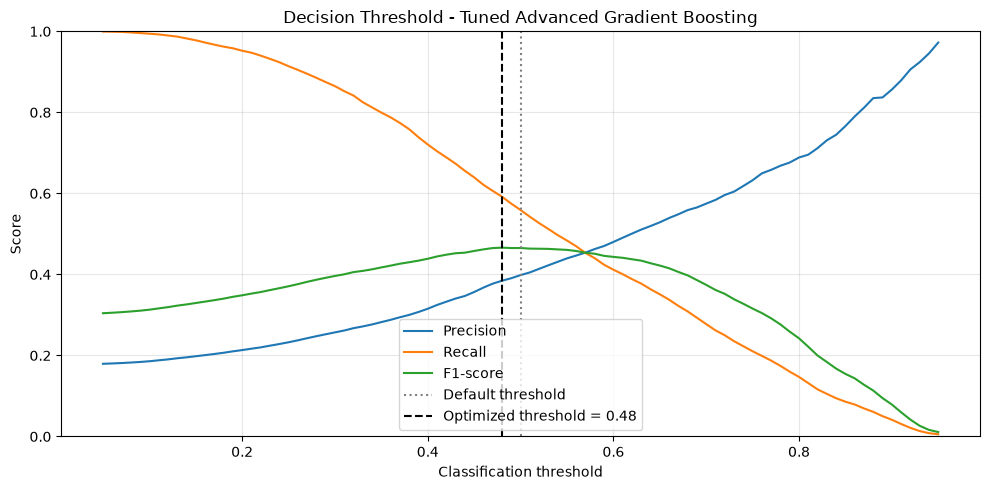

In [40]:
# Cell 41: Final classification threshold optimization
final_threshold_results = []

for threshold in np.linspace(0.05, 0.95, 91):

    y_pred = (y_prob_tuned_gb >= threshold).astype(int)

    final_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, y_pred
        ),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred
        ),
        "F1-score": f1_score(
            y_val, y_pred, zero_division=0
        )
    })

final_threshold_df = pd.DataFrame(
    final_threshold_results
)

best_final_threshold = final_threshold_df.loc[
    final_threshold_df["F1-score"].idxmax(),
    "Threshold"
]

print("Best classification threshold:",
      round(best_final_threshold, 2))

display(
    final_threshold_df.loc[
        final_threshold_df["F1-score"].idxmax()
    ].to_frame().T.round(4)
)

# Visualize threshold performance
plt.figure(figsize=(10, 5))

for metric in ["Precision", "Recall", "F1-score"]:

    plt.plot(
        final_threshold_df["Threshold"],
        final_threshold_df[metric],
        label=metric
    )

plt.axvline(
    0.5,
    linestyle=":",
    color="gray",
    label="Default threshold"
)

plt.axvline(
    best_final_threshold,
    linestyle="--",
    color="black",
    label=f"Optimized threshold = {best_final_threshold:.2f}"
)

plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("Decision Threshold - Tuned Advanced Gradient Boosting")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Cell 42: Final Advanced Gradient Boosting training
final_advanced_gb = clone(tuned_advanced_gb)

start_time = time.time()

final_advanced_gb.fit(
    X_train_advanced,
    y_train_extended
)

final_training_time = time.time() - start_time

print("Final model trained successfully.")
print("Training observations:", len(X_train_advanced))
print("Number of predictors:", len(advanced_features))
print("Training time:", round(final_training_time, 2), "seconds")

Final model trained successfully.
Training observations: 177368
Number of predictors: 18
Training time: 17.51 seconds


In [42]:
# Cell 43: Final Advanced Gradient Boosting evaluation
y_prob_final_gb = final_advanced_gb.predict_proba(
    X_test_advanced
)[:, 1]

advanced_final_results = []

advanced_final_predictions = {}

for threshold_type, threshold in {
    "Default": 0.5,
    "Optimized": best_final_threshold
}.items():

    y_pred = (y_prob_final_gb >= threshold).astype(int)

    advanced_final_predictions[threshold_type] = y_pred

    advanced_final_results.append({
        "Model": "Tuned Advanced Gradient Boosting",
        "Threshold Type": threshold_type,
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test_extended, y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test_extended, y_pred
        ),

        "Precision": precision_score(
            y_test_extended, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test_extended, y_pred
        ),

        "F1-score": f1_score(
            y_test_extended, y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_test_extended, y_prob_final_gb
        ),

        "Average Precision": average_precision_score(
            y_test_extended, y_prob_final_gb
        )
    })

advanced_final_results_df = pd.DataFrame(
    advanced_final_results
)

# Compare with previous test results
complete_final_results = pd.concat([
    final_results_df,
    advanced_final_results_df.assign(
        **{"Feature Set": "Advanced"}
    )
], ignore_index=True)

display(complete_final_results.round(4))

,Feature Set,Model,Threshold Type,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Basic,Baseline,Default,0.50,0.8560,0.5000,0.0000,0.0000,0.0000,0.5000,0.1440
1,Basic,Logistic Regression,Default,0.50,0.6691,0.5344,0.1735,0.3452,0.2309,0.5549,0.1759
2,Basic,Decision Tree,Default,0.50,0.8042,0.5139,0.1855,0.1063,0.1351,0.5507,0.1677
3,Basic,Random Forest,Default,0.50,0.6280,0.5447,0.1753,0.4278,0.2487,0.5746,0.1827
4,Extended,Baseline,Default,0.50,0.8560,0.5000,0.0000,0.0000,0.0000,0.5000,0.1440
5,Extended,Logistic Regression,Default,0.50,0.8081,0.6757,0.3731,0.4898,0.4235,0.7532,0.3713
6,Extended,Logistic Regression,Optimized,0.52,0.8167,0.6697,0.3860,0.4632,0.4211,0.7532,0.3713
7,Extended,Decision Tree,Default,0.50,0.7813,0.6812,0.3377,0.5406,0.4157,0.7551,0.3830
8,Extended,Decision Tree,Optimized,0.53,0.7958,0.6738,0.3530,0.5025,0.4147,0.7551,0.3830
9,Extended,Random Forest,Default,0.50,0.7853,0.6913,0.3474,0.5592,0.4286,0.7731,0.4103


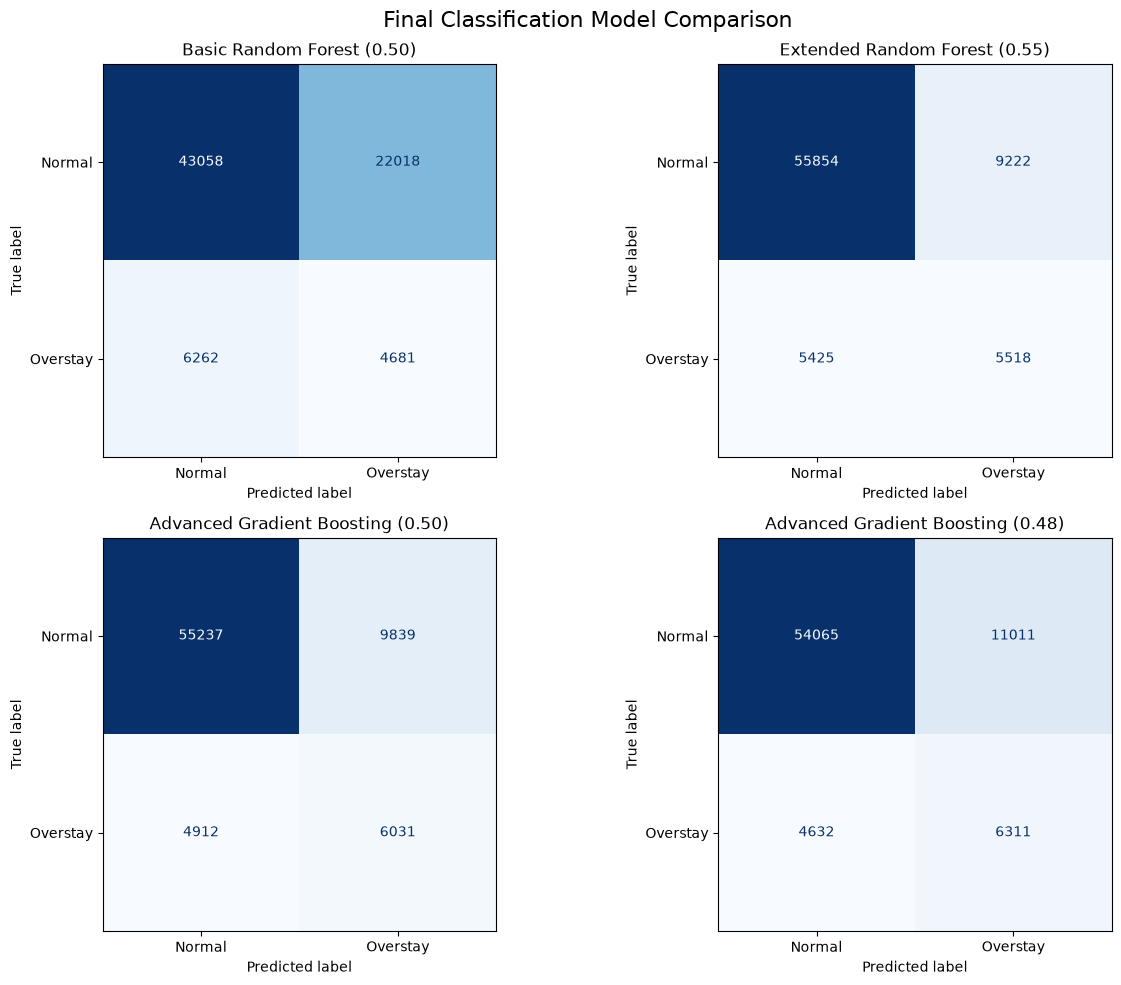

In [43]:
# Cell 44: Final comparison of classification models
final_cm_models = {
    "Basic Random Forest (0.50)":
        final_predictions[
            ("Basic", "Random Forest", "Default")
        ],

    "Extended Random Forest (0.55)":
        final_predictions[
            ("Extended", "Random Forest", "Optimized")
        ],

    "Advanced Gradient Boosting (0.50)":
        advanced_final_predictions["Default"],

    "Advanced Gradient Boosting (0.48)":
        advanced_final_predictions["Optimized"]
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, y_pred) in zip(
    axes.ravel(), final_cm_models.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test_extended,
        y_pred,
        labels=[0, 1],
        display_labels=["Normal", "Overstay"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle(
    "Final Classification Model Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

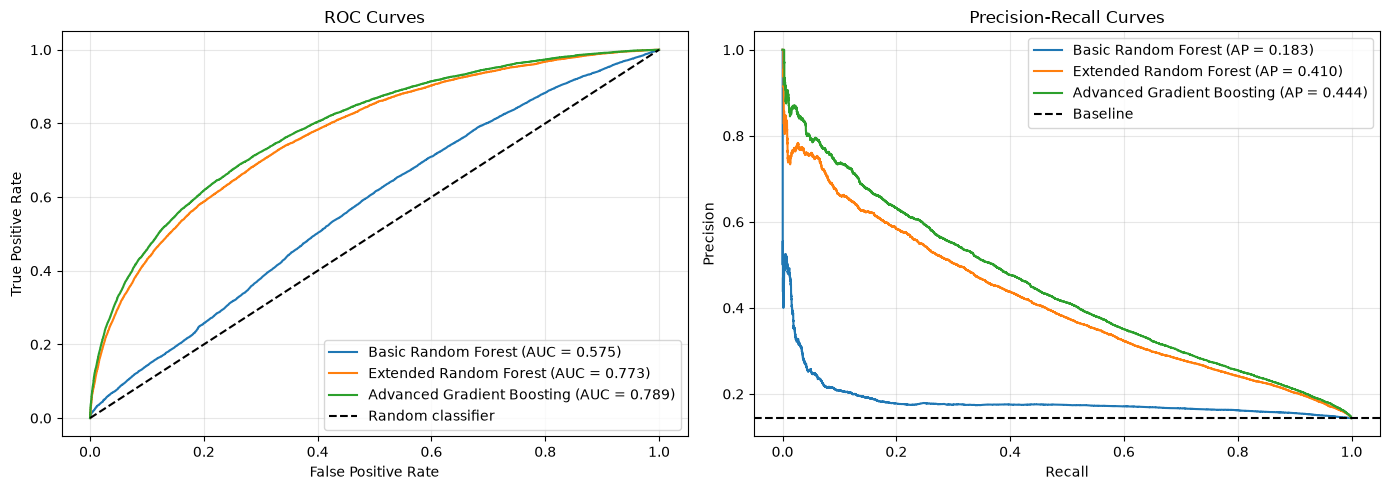

In [44]:
# Cell 45: Final ROC and precision-recall curves
final_score_models = {
    "Basic Random Forest":
        final_probabilities[
            ("Basic", "Random Forest")
        ],

    "Extended Random Forest":
        final_probabilities[
            ("Extended", "Random Forest")
        ],

    "Advanced Gradient Boosting":
        y_prob_final_gb
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, y_prob in final_score_models.items():

    # ROC curve
    fpr, tpr, _ = roc_curve(
        y_test_extended, y_prob
    )

    auc_score = roc_auc_score(
        y_test_extended, y_prob
    )

    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

    # Precision-recall curve
    precision, recall, _ = precision_recall_curve(
        y_test_extended, y_prob
    )

    ap_score = average_precision_score(
        y_test_extended, y_prob
    )

    axes[1].plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.3f})"
    )

axes[0].plot(
    [0, 1], [0, 1],
    "--",
    color="black",
    label="Random classifier"
)

axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].axhline(
    y=y_test_extended.mean(),
    linestyle="--",
    color="black",
    label="Baseline"
)

axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Feature,Importance,Std
6,hist_user_sessions,0.0137,0.0005
15,hist_idle_last10,0.0137,0.0012
7,hist_user_overstay_rate,0.0128,0.0010
13,hist_overstay_last10,0.0111,0.0004
8,hist_user_mean_idle,0.0062,0.0009
14,hist_idle_last5,0.0061,0.0005
10,hist_user_hours_since_last,0.0060,0.0004
0,start_hour,0.0047,0.0004
16,hist_last_idle,0.0032,0.0002
17,hist_idle_std,0.0015,0.0002


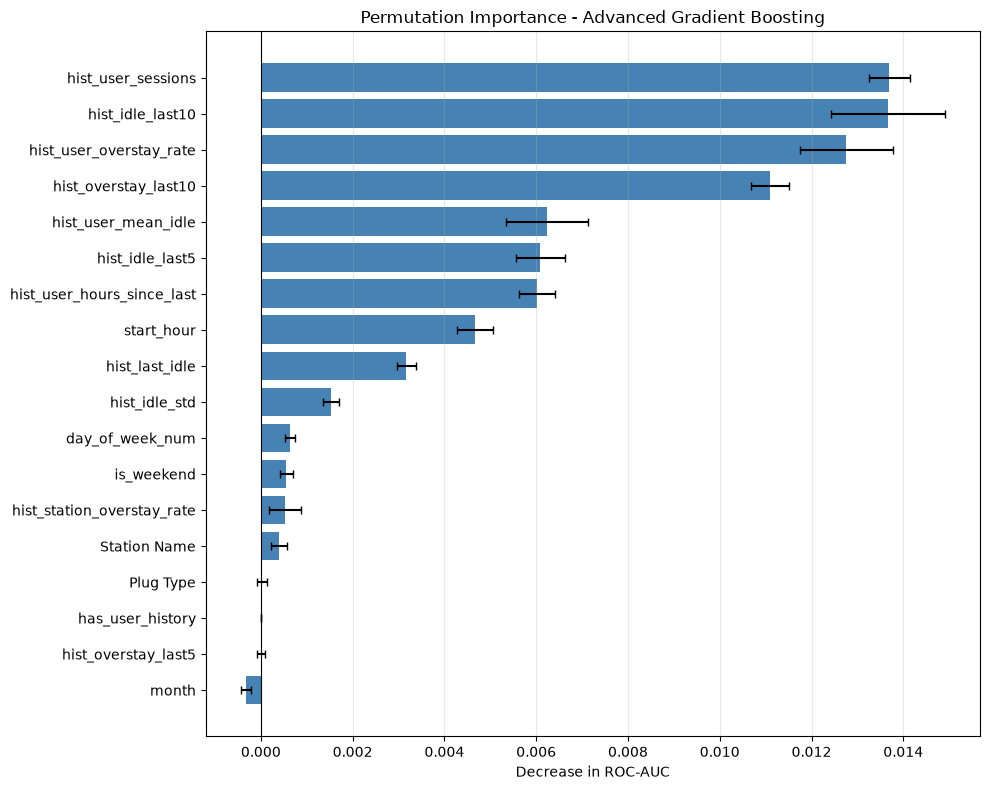

In [45]:
# Cell 46: Advanced Gradient Boosting feature importance
advanced_importance = permutation_importance(
    tuned_advanced_gb,
    X_val_advanced,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

advanced_importance_df = pd.DataFrame({
    "Feature": advanced_features,
    "Importance": advanced_importance.importances_mean,
    "Std": advanced_importance.importances_std
}).sort_values("Importance", ascending=False)

display(advanced_importance_df.round(4))

plot_df = advanced_importance_df.sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="steelblue",
    capsize=3
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Decrease in ROC-AUC")
plt.title("Permutation Importance - Advanced Gradient Boosting")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
# Cell 47: Updated business impact analysis
business_df_final = advanced_model_df.loc[
    X_test_advanced.index,
    ["idle_minutes", target]
].copy()

# Verify target alignment
assert business_df_final[target].equals(y_test_extended)

# Calculate excess idle hours
business_df_final["excess_idle_hours"] = (
    business_df_final["idle_minutes"] - OVERSTAY_THRESHOLD_MINS
).clip(lower=0) / 60

total_excess_hours_final = (
    business_df_final["excess_idle_hours"].sum()
)

# Select models for operational comparison
business_models = {
    "Basic RF (0.50)":
        final_predictions[
            ("Basic", "Random Forest", "Default")
        ],

    "Extended RF (0.50)":
        final_predictions[
            ("Extended", "Random Forest", "Default")
        ],

    "Extended RF (0.55)":
        final_predictions[
            ("Extended", "Random Forest", "Optimized")
        ],

    "Advanced GB (0.50)":
        advanced_final_predictions["Default"],

    "Advanced GB (0.48)":
        advanced_final_predictions["Optimized"]
}

final_business_results = []

actual_overstay = (
    business_df_final[target].to_numpy() == 1
)

for name, y_pred in business_models.items():

    predicted_overstay = y_pred == 1

    true_positives = predicted_overstay & actual_overstay
    false_positives = predicted_overstay & ~actual_overstay

    captured_hours = business_df_final.loc[
        true_positives, "excess_idle_hours"
    ].sum()

    missed_hours = (
        total_excess_hours_final - captured_hours
    )

    final_business_results.append({
        "Model": name,
        "Notifications": predicted_overstay.sum(),
        "Correct Notifications": true_positives.sum(),
        "Unnecessary Notifications": false_positives.sum(),
        "Identified Excess Hours": captured_hours,
        "Missed Excess Hours": missed_hours,
        "Excess Hours Captured (%)": (
            captured_hours / total_excess_hours_final * 100
        ),
        "Hours per Notification": (
            captured_hours / max(predicted_overstay.sum(), 1)
        )
    })

final_business_df = pd.DataFrame(
    final_business_results
)

print(
    f"Total excess idle hours: "
    f"{total_excess_hours_final:,.2f}"
)

display(final_business_df.round(2))

Total excess idle hours: 12,708.83


,Model,Notifications,Correct Notifications,Unnecessary Notifications,Identified Excess Hours,Missed Excess Hours,Excess Hours Captured (%),Hours per Notification
0,Basic RF (0.50),26699,4681,22018,5731.93,6976.90,45.10,0.21
1,Extended RF (0.50),17613,6119,11494,8052.22,4656.60,63.36,0.46
2,Extended RF (0.55),14740,5518,9222,7523.47,5185.36,59.20,0.51
3,Advanced GB (0.50),15870,6031,9839,8020.00,4688.83,63.11,0.51
4,Advanced GB (0.48),17322,6311,11011,8225.88,4482.94,64.73,0.47


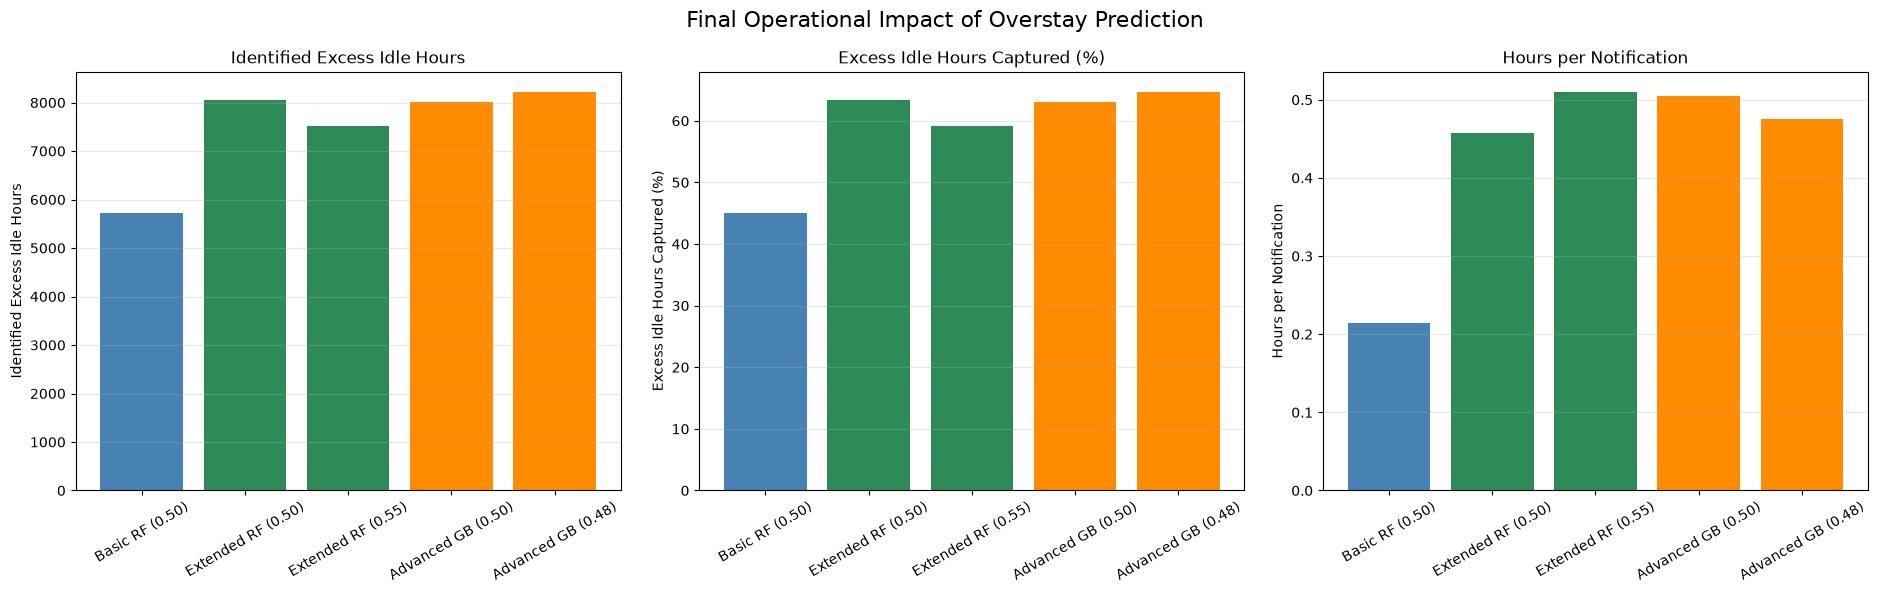

In [47]:
# Cell 48: Final operational performance comparison
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

business_metrics = [
    ("Identified Excess Hours", "Identified Excess Idle Hours"),
    ("Excess Hours Captured (%)", "Excess Idle Hours Captured (%)"),
    ("Hours per Notification", "Hours per Notification")
]

colors = [
    "steelblue",
    "seagreen",
    "seagreen",
    "darkorange",
    "darkorange"
]

for ax, (metric, title) in zip(axes, business_metrics):

    ax.bar(
        final_business_df["Model"],
        final_business_df[metric],
        color=colors
    )

    ax.set_title(title)
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Final Operational Impact of Overstay Prediction",
    fontsize=16
)

plt.tight_layout()
plt.show()

,Intervention Effectiveness (%),Recovered Charger Hours,Recovered Charger Days,Total Excess Hours Recovered (%)
0,10.0,822.59,34.27,6.47
1,25.0,2056.47,85.69,16.18
2,50.0,4112.94,171.37,32.36
3,75.0,6169.41,257.06,48.54
4,100.0,8225.88,342.75,64.73


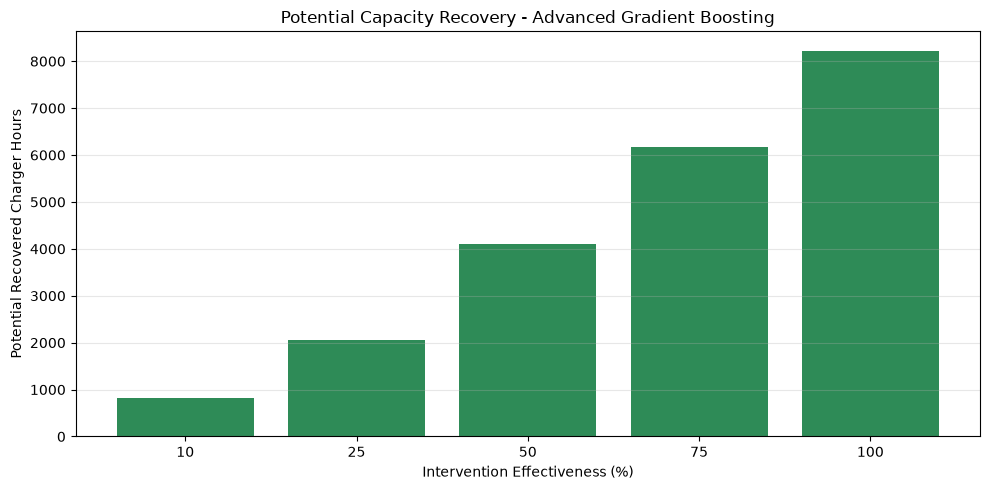

In [48]:
# Cell 49: Potential charging capacity recovery
selected_result = final_business_df[
    final_business_df["Model"] == "Advanced GB (0.48)"
].iloc[0]

identified_hours = selected_result["Identified Excess Hours"]

effectiveness_levels = [0.10, 0.25, 0.50, 0.75, 1.00]

final_scenarios = []

for effectiveness in effectiveness_levels:

    recovered_hours = identified_hours * effectiveness

    final_scenarios.append({
        "Intervention Effectiveness (%)": effectiveness * 100,
        "Recovered Charger Hours": recovered_hours,
        "Recovered Charger Days": recovered_hours / 24,
        "Total Excess Hours Recovered (%)": (
            recovered_hours / total_excess_hours_final * 100
        )
    })

final_scenario_df = pd.DataFrame(final_scenarios)

display(final_scenario_df.round(2))

plt.figure(figsize=(10, 5))

plt.bar(
    final_scenario_df[
        "Intervention Effectiveness (%)"
    ].astype(int).astype(str),
    final_scenario_df["Recovered Charger Hours"],
    color="seagreen"
)

plt.xlabel("Intervention Effectiveness (%)")
plt.ylabel("Potential Recovered Charger Hours")
plt.title("Potential Capacity Recovery - Advanced Gradient Boosting")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()